# Project 2 — Day-Ahead Forecasting of EV Charging Demand

This project develops and evaluates forecasting methods for predicting electric-vehicle charging demand over a 24-hour horizon. Using historical transaction-level data, charging sessions will be aggregated into hourly time series and forecast at both the network level and across the three geographical districts.

The analysis will investigate how historical charging activity, temporal patterns, and other information available at the forecast issuance time can support accurate day-ahead predictions. Forecasting performance will be assessed across horizons, locations, and time periods using predictive accuracy, temporal stability, computational requirements, and operational usefulness.

The results aim to support charging-infrastructure operators in capacity planning, resource allocation, tariff design, and the identification of future demand peaks.

## Main Imports

In [107]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
)
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.statespace.sarimax import SARIMAX


## Task 1 — Time-Series Construction, Exploratory Analysis, and Forecasting Framework

Transform the supplied transaction-level dataset into coherent time series suitable for forecasting charging 
demand  at  both  the  complete  network  and  district  levels  and  formally  establish  the  forecasting  and 
evaluation methodology prior to model development.

### Loading the Data

In [2]:
df = pd.read_csv("../data/Charging_Data.csv", encoding="cp1252")

## Data Overview

In [3]:
df.shape

(441077, 24)

In [4]:
df.head()

,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,...,Relative Humidity(%),Precipitation(mm),end_cause,is_full_charge,is_user_stop,is_nonsystem_fault,is_system_issue,is_EV_fault,is_other_fault,is_abnormal
0,1,1,Tourist Attraction,Nanhu,2020-12-31 23:35:55\t,6.24,2.60,3.74,6.34,6.34,...,45,0.0,User stops charging,0,1,0,0,0,0,0
1,2,2,Tourist Attraction,Nanhu,2020-12-31 23:35:17\t,0.62,0.26,0.37,0.63,0.63,...,45,0.0,User stops charging,0,1,0,0,0,0,0
2,3,3,Tourist Attraction,Nanhu,2020-12-31 22:01:34\t,28.01,11.66,16.81,28.47,28.47,...,45,0.0,User stops charging,0,1,0,0,0,0,0
3,4,2,Tourist Attraction,Nanhu,2020-12-31 22:21:37\t,5.20,2.17,3.12,5.29,5.29,...,45,0.0,User stops charging,0,1,0,0,0,0,0
4,5,1,Tourist Attraction,Nanhu,2020-12-31 22:10:30\t,4.58,1.91,2.75,4.66,4.66,...,45,0.0,Charging ends normally,1,0,0,0,0,0,0


In [5]:
df.tail()

,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,...,Relative Humidity(%),Precipitation(mm),end_cause,is_full_charge,is_user_stop,is_nonsystem_fault,is_system_issue,is_EV_fault,is_other_fault,is_abnormal
441072,604,87,Wholesale Market,Xiuzhou,2021-01-01 00:06:09\t,28.15,11.72,16.89,28.61,28.61,...,57,0.0,User stops charging,0,1,0,0,0,0,0
441073,9813,92,Wholesale Market,Xiuzhou,2020-12-31 22:54:10\t,24.79,10.32,14.87,25.19,25.19,...,45,0.0,User stops charging,0,1,0,0,0,0,0
441074,309,87,Wholesale Market,Xiuzhou,2020-12-31 22:47:14\t,33.20,13.82,19.92,33.74,33.74,...,45,0.0,Charging ends normally,1,0,0,0,0,0,0
441075,604,91,Wholesale Market,Xiuzhou,2021-01-01 00:01:45\t,0.39,0.16,0.23,0.39,0.39,...,57,0.0,DC Output Fault,0,0,1,0,0,0,1
441076,5031,85,Wholesale Market,Xiuzhou,2020-12-31 23:43:19\t,9.59,3.99,5.75,9.74,9.74,...,45,0.0,Charging ends normally,1,0,0,0,0,0,0


In [6]:
df.columns.tolist()

['UserID',
 'Charging Post ID',
 'Location Information',
 'District Name',
 'Order creation time',
 'Transaction power/kwh',
 'Electricity cost/Yuan',
 'Service charge/Yuan',
 'Transaction Amount/Yuan',
 'Actual Payment/Yuan',
 'Start Time',
 'End Time',
 'Payment time',
 'Temperature(¡æ)',
 'Relative Humidity(%)',
 'Precipitation(mm)',
 'end_cause',
 'is_full_charge',
 'is_user_stop',
 'is_nonsystem_fault',
 'is_system_issue',
 'is_EV_fault',
 'is_other_fault',
 'is_abnormal']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 441077 entries, 0 to 441076
Data columns (total 24 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   UserID                   441077 non-null  int64  
 1   Charging Post ID         441077 non-null  int64  
 2   Location Information     441077 non-null  str    
 3   District Name            441077 non-null  str    
 4   Order creation time      441077 non-null  str    
 5   Transaction power/kwh    441077 non-null  float64
 6   Electricity cost/Yuan    441077 non-null  float64
 7   Service charge/Yuan      441077 non-null  float64
 8   Transaction Amount/Yuan  441077 non-null  float64
 9   Actual Payment/Yuan      441077 non-null  float64
 10  Start Time               441077 non-null  str    
 11  End Time                 441077 non-null  str    
 12  Payment time             441077 non-null  str    
 13  Temperature(¡æ)          441077 non-null  float64
 14  Relative Humidi

In [8]:
binary_columns = [
    column for column in df.columns
    if df[column].dropna().isin([0, 1]).all()
]

binary_columns

['is_full_charge',
 'is_user_stop',
 'is_nonsystem_fault',
 'is_system_issue',
 'is_EV_fault',
 'is_other_fault',
 'is_abnormal']

In [19]:
datetime_columns = ['Start Time', 'End Time', 'Payment time', 'Order creation time']

In [10]:
id_columns = ['UserID', 'Charging Post ID']

In [11]:
df.isnull().sum()

UserID                     0
Charging Post ID           0
Location Information       0
District Name              0
Order creation time        0
Transaction power/kwh      0
Electricity cost/Yuan      0
Service charge/Yuan        0
Transaction Amount/Yuan    0
Actual Payment/Yuan        0
Start Time                 0
End Time                   0
Payment time               0
Temperature(¡æ)            0
Relative Humidity(%)       0
Precipitation(mm)          0
end_cause                  0
is_full_charge             0
is_user_stop               0
is_nonsystem_fault         0
is_system_issue            0
is_EV_fault                0
is_other_fault             0
is_abnormal                0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.nunique()

UserID                      56115
Charging Post ID               92
Location Information           13
District Name                   3
Order creation time        438764
Transaction power/kwh        7053
Electricity cost/Yuan        6320
Service charge/Yuan          5129
Transaction Amount/Yuan      8487
Actual Payment/Yuan          8412
Start Time                 438689
End Time                   438679
Payment time               421831
Temperature(¡æ)               318
Relative Humidity(%)           67
Precipitation(mm)             235
end_cause                      15
is_full_charge                  2
is_user_stop                    2
is_nonsystem_fault              2
is_system_issue                 2
is_EV_fault                     2
is_other_fault                  2
is_abnormal                     2
dtype: int64

In [14]:
df.rename(columns={"Temperature(¡æ)": "Temperature(ºC)"}, inplace=True)

In [15]:
numerical_non_binary = df.select_dtypes(include=[np.number]).drop(columns=binary_columns).drop(columns=id_columns)
numerical_non_binary.describe().T

,count,mean,std,min,25%,50%,75%,max
Transaction power/kwh,441077.0,16.436574,13.253881,0.0,5.44,15.15,24.74,117.74
Electricity cost/Yuan,441077.0,12.158460,10.830214,0.0,3.34,10.11,18.16,121.16
Service charge/Yuan,441077.0,7.450791,8.152830,0.0,1.07,5.10,10.99,101.26
Transaction Amount/Yuan,441077.0,19.609251,15.958935,0.0,6.27,18.44,29.70,147.17
Actual Payment/Yuan,441077.0,18.487883,15.924672,0.0,4.60,16.65,29.37,147.17
Temperature(ºC),441077.0,19.708336,8.481954,-3.2,12.70,21.00,26.90,33.60
Relative Humidity(%),441077.0,75.030351,12.656150,32.0,67.00,76.00,84.00,99.00
Precipitation(mm),441077.0,3.510698,10.833238,0.0,0.00,0.00,1.20,152.10


## Numerical Variable Summary

The descriptive statistics show that each numerical variable contains 441,077 observations and no apparent missing values.

- **Transaction power** averages 16.44 kWh, with values ranging from 0 to 117.74 kWh.
- **Financial variables** are positively skewed, with means generally exceeding their medians. Transaction amounts range up to 147.17 Yuan.
- **Actual payment** is slightly lower than the transaction amount on average, suggesting the presence of discounts or adjustments.
- **Temperature** ranges from −3.2°C to 33.6°C, with a mean of 19.71°C.
- **Relative humidity** averages 75.03% and ranges from 32% to 99%.
- **Precipitation** is highly skewed: the median is 0 mm, while the maximum reaches 152.10 mm.

In [16]:
binary = df[binary_columns]
binary_counts = binary.apply(pd.Series.value_counts).T
binary_counts.columns = ['0 (No)', '1 (Yes)']
binary_counts 

,0 (No),1 (Yes)
is_full_charge,237876,203201
is_user_stop,285135,155942
is_nonsystem_fault,399799,41278
is_system_issue,440900,177
is_EV_fault,420712,20365
is_other_fault,420963,20114
is_abnormal,359143,81934


## Binary Variable Distribution

The binary indicators show the following patterns:

- **Full-charge sessions** represent 203,201 observations (46.07%).
- **User-terminated sessions** account for 155,942 observations (35.36%).
- **Non-system faults** occur in 41,278 observations (9.36%).
- **System issues** are rare, occurring in only 177 observations (0.04%).
- **EV faults** and **other faults** occur in 20,365 (4.62%) and 20,114 (4.56%) observations, respectively.
- **Abnormal sessions** account for 81,934 observations (18.57%).

These indicators may overlap because a single charging session can be associated with multiple conditions.

In [20]:
for column in datetime_columns:
    df[column] = pd.to_datetime(
        df[column].astype('string').str.strip(),
    )

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 441077 entries, 0 to 441076
Data columns (total 24 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   UserID                   441077 non-null  int64         
 1   Charging Post ID         441077 non-null  int64         
 2   Location Information     441077 non-null  str           
 3   District Name            441077 non-null  str           
 4   Order creation time      441077 non-null  datetime64[us]
 5   Transaction power/kwh    441077 non-null  float64       
 6   Electricity cost/Yuan    441077 non-null  float64       
 7   Service charge/Yuan      441077 non-null  float64       
 8   Transaction Amount/Yuan  441077 non-null  float64       
 9   Actual Payment/Yuan      441077 non-null  float64       
 10  Start Time               441077 non-null  datetime64[us]
 11  End Time                 441077 non-null  datetime64[us]
 12  Payment time             44

### Construct the Time Series

In [34]:
demand_data = df[['Start Time', 'District Name', 'Transaction power/kwh']]

demand_data = demand_data[demand_data['Transaction power/kwh'] > 0]

demand_data

,Start Time,District Name,Transaction power/kwh
0,2020-12-31 23:35:43,Nanhu,6.24
1,2020-12-31 23:35:19,Nanhu,0.62
2,2020-12-31 22:00:05,Nanhu,28.01
3,2020-12-31 22:21:38,Nanhu,5.20
4,2020-12-31 22:10:31,Nanhu,4.58
...,...,...,...
441072,2021-01-01 00:06:13,Xiuzhou,28.15
441073,2020-12-31 22:54:11,Xiuzhou,24.79
441074,2020-12-31 22:47:15,Xiuzhou,33.20
441075,2021-01-01 00:01:48,Xiuzhou,0.39


In [54]:
start = demand_data['Start Time'].min().floor('h')
end = demand_data['Start Time'].max().floor('h')

hourly_index = pd.date_range(
    start=start,
    end=end,
    freq='h'
)

network_demand = (
    demand_data
    .groupby(demand_data['Start Time'].dt.floor('h'))['Transaction power/kwh']
    .sum()
    .reindex(hourly_index, fill_value=0)
    .rename('Network')
)
network_demand

2019-12-31 21:00:00     49.68
2019-12-31 22:00:00    103.55
2019-12-31 23:00:00    309.47
2020-01-01 00:00:00    242.69
2020-01-01 01:00:00     58.31
                        ...  
2021-12-31 19:00:00    962.89
2021-12-31 20:00:00    913.80
2021-12-31 21:00:00    853.93
2021-12-31 22:00:00    921.94
2021-12-31 23:00:00    111.78
Freq: h, Name: Network, Length: 17547, dtype: float64

In [55]:
district_demand = (
    demand_data.pivot_table(
        index=demand_data['Start Time'].dt.floor('h'),
        columns='District Name',
        values='Transaction power/kwh',
        aggfunc='sum',
        fill_value=0
    )
    .reindex(hourly_index, fill_value=0)
)
district_demand

District Name,Nanhu,Tongxiang,Xiuzhou
2019-12-31 21:00:00,0.00,37.65,12.03
2019-12-31 22:00:00,0.00,103.55,0.00
2019-12-31 23:00:00,0.00,233.48,75.99
2020-01-01 00:00:00,0.00,164.74,77.95
2020-01-01 01:00:00,8.90,49.41,0.00
...,...,...,...
2021-12-31 19:00:00,31.91,626.87,304.11
2021-12-31 20:00:00,74.82,476.09,362.89
2021-12-31 21:00:00,0.00,638.48,215.45
2021-12-31 22:00:00,89.21,495.45,337.28


In [56]:
hourly_demand = pd.concat([network_demand, district_demand], axis=1)
hourly_demand.index.name = 'Start Time'
hourly_demand

,Network,Nanhu,Tongxiang,Xiuzhou
Start Time,,,,
2019-12-31 21:00:00,49.68,0.00,37.65,12.03
2019-12-31 22:00:00,103.55,0.00,103.55,0.00
2019-12-31 23:00:00,309.47,0.00,233.48,75.99
2020-01-01 00:00:00,242.69,0.00,164.74,77.95
2020-01-01 01:00:00,58.31,8.90,49.41,0.00
...,...,...,...,...
2021-12-31 19:00:00,962.89,31.91,626.87,304.11
2021-12-31 20:00:00,913.80,74.82,476.09,362.89
2021-12-31 21:00:00,853.93,0.00,638.48,215.45


## Temporal Exploration and Interpretation

The hourly demand series will be examined at the network and district levels to identify long-term trends, recurring seasonal patterns, structural changes, and differences in demand intensity.

### Verify the Time-Series Structure

In [69]:
# Verify hourly continuity
index_differences_check = hourly_demand.index.to_series().diff().dropna()
is_hourly_continuous_check = index_differences_check.eq(pd.Timedelta(hours=1)).all()

# Identify missing timestamps and zero-demand periods
expected_index_check = pd.date_range(
    hourly_demand.index.min(),
    hourly_demand.index.max(),
    freq="h"
)
missing_timestamps_check = expected_index_check.difference(hourly_demand.index)
zero_demand_timestamps_check = hourly_demand.index[hourly_demand["Network"].eq(0)]

# Verify network demand equals district totals
district_total_check = district_demand.sum(axis=1)
network_matches_districts_check = np.isclose(
    hourly_demand["Network"],
    district_total_check
).all()

# Identify complete calendar days
hours_per_day_check = hourly_demand.groupby(hourly_demand.index.normalize()).size()
complete_days_check = hours_per_day_check[hours_per_day_check.eq(24)]

verification_summary_check = pd.Series({
    "Hourly and continuous": is_hourly_continuous_check,
    "Missing timestamps": len(missing_timestamps_check),
    "Zero-demand hours": len(zero_demand_timestamps_check),
    "Network equals district total": network_matches_districts_check,
    "Observation start": hourly_demand.index.min(),
    "Observation end": hourly_demand.index.max(),
    "Observation period": hourly_demand.index.max() - hourly_demand.index.min(),
    "Complete days": len(complete_days_check),
})

Hourly and continuous                           True
Missing timestamps                                 0
Zero-demand hours                                491
Network equals district total                   True
Observation start                2019-12-31 21:00:00
Observation end                  2021-12-31 23:00:00
Observation period                 731 days 02:00:00
Complete days                                    731
dtype: object

### Network Demand

In [74]:
# Aggregate network demand at multiple time scales
daily_network = network_demand.resample("D").sum()
weekly_network = daily_network.resample("W-MON", label="left", closed="left").sum()
monthly_network = daily_network.resample("MS").sum()

# Rolling averages
hourly_rolling_7d = network_demand.rolling("7D", min_periods=24).mean()
daily_rolling_7d = daily_network.rolling(7, min_periods=3).mean()

# Identify unusually high and low daily demand
daily_z_scores = (
    (daily_network - daily_network.mean()) / daily_network.std()
)
unusual_daily_demand = daily_network[
    daily_z_scores.abs() >= 3
].sort_values(ascending=False)

# Summary statistics
network_demand_summary = pd.Series({
    "Hourly mean": network_demand.mean(),
    "Hourly maximum": network_demand.max(),
    "Hourly peak time": network_demand.idxmax(),
    "Daily mean": daily_network.mean(),
    "Daily maximum": daily_network.max(),
    "Daily peak date": daily_network.idxmax(),
    "Weekly maximum": weekly_network.max(),
    "Monthly maximum": monthly_network.max(),
})

display(network_demand_summary)
display(unusual_daily_demand.head(10))

Hourly mean                  413.164334
Hourly maximum                  1363.87
Hourly peak time    2021-11-24 11:00:00
Daily mean                  9904.090943
Daily maximum                  17180.71
Daily peak date     2021-10-01 00:00:00
Weekly maximum                112451.22
Monthly maximum               455802.95
dtype: object

Series([], Freq: D, Name: Network, dtype: float64)

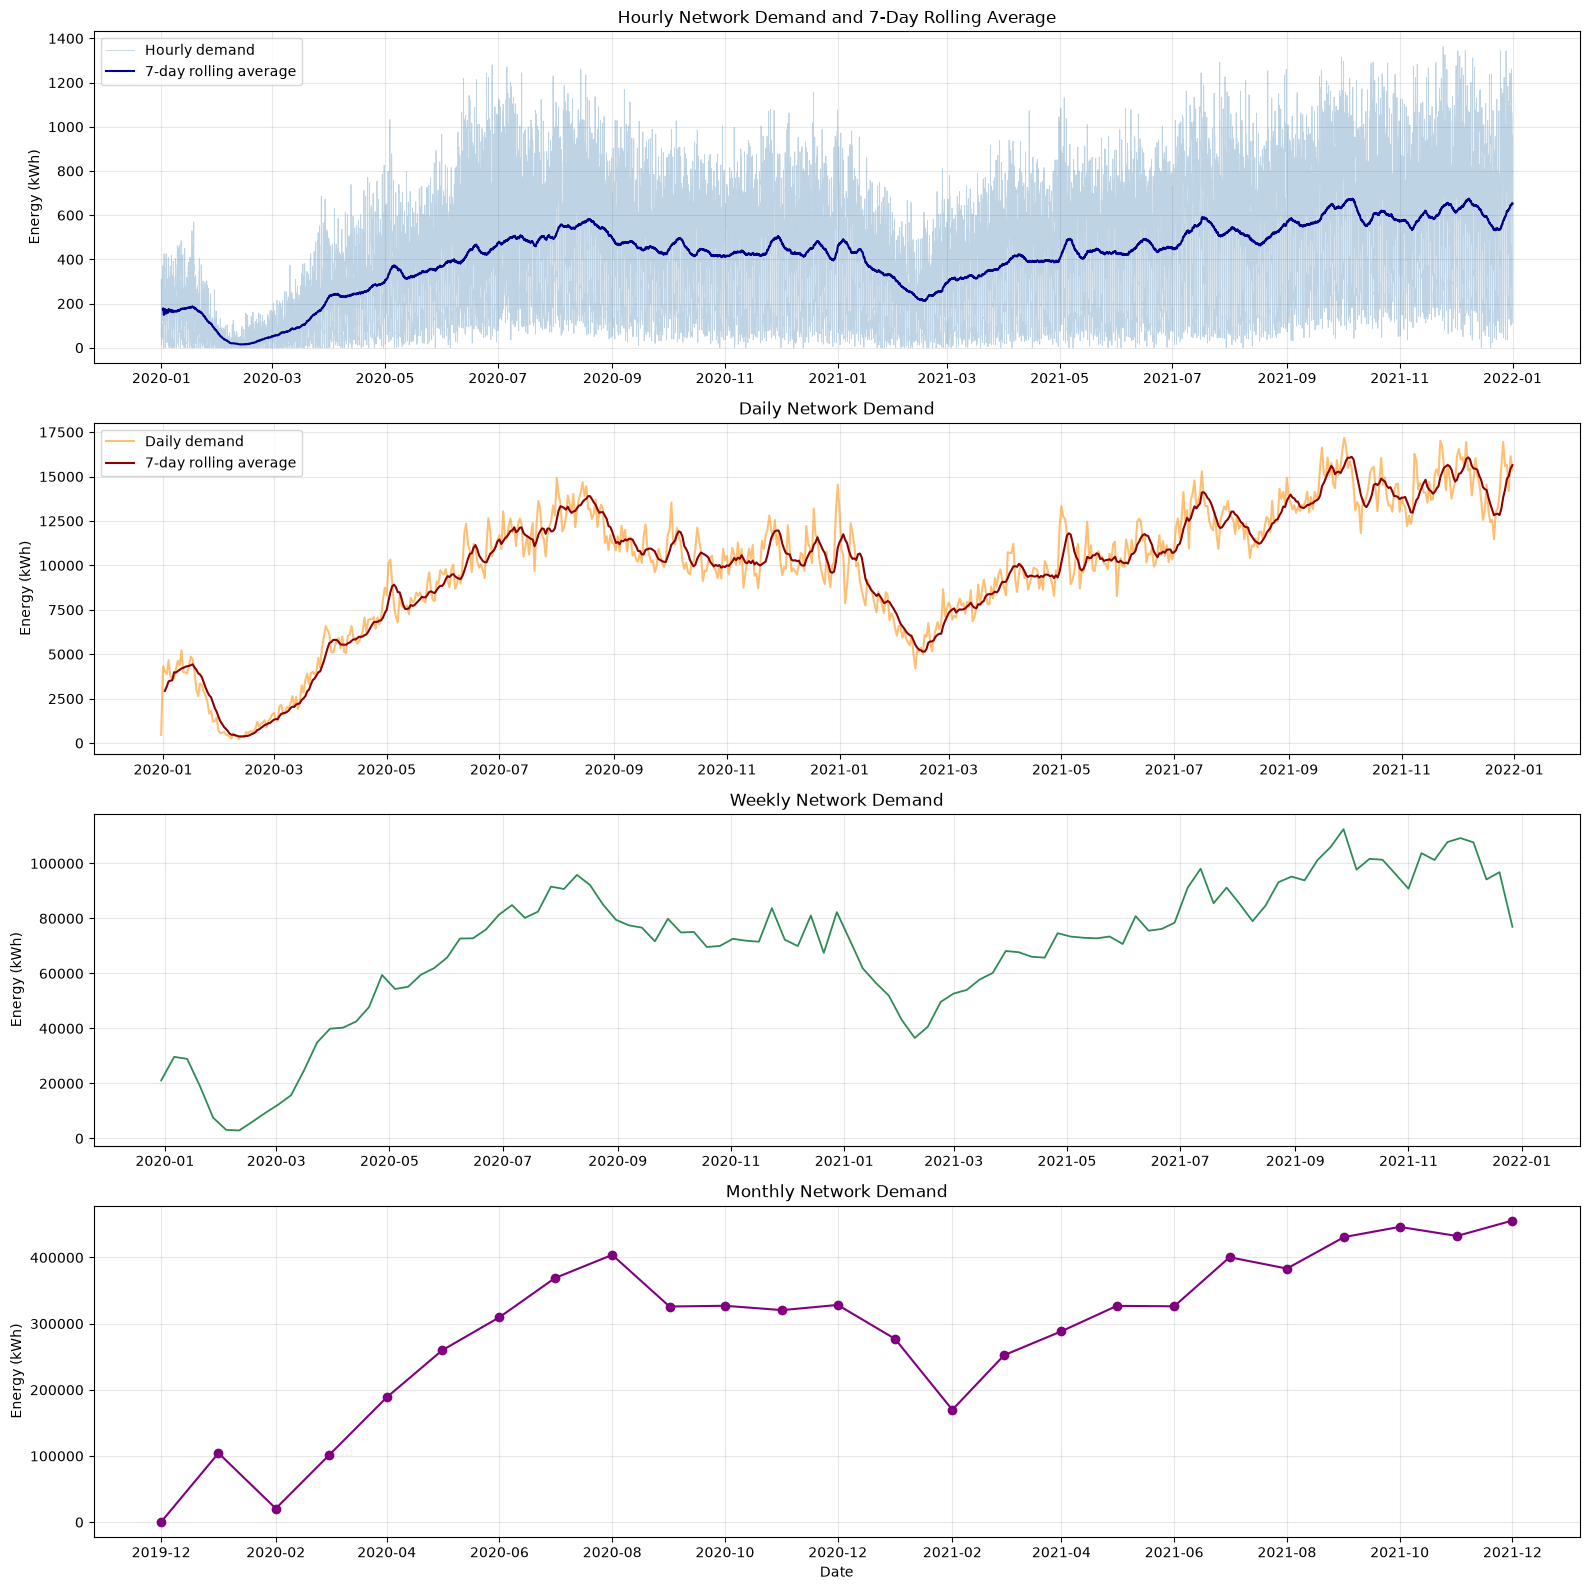

In [76]:
# Visualise hourly, daily, weekly, and monthly demand
fig, axes = plt.subplots(4, 1, figsize=(16, 16))

# 1. Hourly (axes[0])
axes[0].plot(
    network_demand.index,
    network_demand.values,
    color="steelblue",
    alpha=0.35,
    linewidth=0.6,
    label="Hourly demand",
)
axes[0].plot(
    hourly_rolling_7d.index,
    hourly_rolling_7d.values,
    color="darkblue",
    linewidth=1.5,
    label="7-day rolling average",
)
axes[0].set_title("Hourly Network Demand and 7-Day Rolling Average")
axes[0].set_ylabel("Energy (kWh)")
axes[0].legend()

# 2. Daily (axes[1])
axes[1].plot(
    daily_network.index,
    daily_network.values,
    color="darkorange",
    alpha=0.55,
    label="Daily demand",
)
axes[1].plot(
    daily_rolling_7d.index,
    daily_rolling_7d.values,
    color="darkred",
    linewidth=1.5,
    label="7-day rolling average",
)
axes[1].set_title("Daily Network Demand")
axes[1].set_ylabel("Energy (kWh)")
axes[1].legend()

# 3. Weekly (axes[2])
axes[2].plot(
    weekly_network.index,
    weekly_network.values,
    color="seagreen",
    linewidth=1.3,
)
axes[2].set_title("Weekly Network Demand")
axes[2].set_ylabel("Energy (kWh)")

# 4. Monthly (axes[3])
axes[3].plot(
    monthly_network.index,
    monthly_network.values,
    color="purple",
    marker="o",
    linewidth=1.5,
)
axes[3].set_title("Monthly Network Demand")
axes[3].set_ylabel("Energy (kWh)")
axes[3].set_xlabel("Date")

# Format x-axis for all subplots
for axis in axes:
    axis.grid(alpha=0.3)
    axis.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.tight_layout()
plt.show()

## Network Demand Findings

- **Demand is increasing over time.** Monthly demand rises from approximately 104,416 kWh in January 2020 to 455,803 kWh in December 2021. Although there are temporary declines, particularly in early 2021, demand generally increases across the observation period.

- **Demand includes several periods of reduced activity.** The most notable reductions occur in February 2020, January–February 2021, and around individual zero-demand hours. These periods may reflect operational, behavioural, or data-collection effects and should be considered when developing forecasting models.

- **The largest observed peaks occur toward the end of the dataset.** The maximum hourly demand is 1,363.87 kWh on 24 November 2021 at 11:00, while the maximum daily demand is 17,180.71 kWh on 1 October 2021. This indicates that peak demand becomes more substantial as the network expands.

- **Demand variability also appears to increase over time.** The hourly series becomes more dispersed during 2021, with larger fluctuations around its rolling average and more frequent high-demand observations. This suggests that forecasting models should account for changing variance, seasonal effects, and possible growth in network usage.

- No daily observations were identified using the current three-standard-deviation threshold. However, the absence of statistical outliers does not exclude operationally important peaks, so peak magnitude and rolling variability should also be monitored.

##### Intraday Seasonality

,Mean,Median,Standard_Deviation,Minimum,Maximum
Hour of Day,,,,,
0,302.87,306.79,168.08,0.0,858.31
1,189.18,171.08,125.91,0.0,629.55
2,133.68,123.98,96.09,0.0,468.03
3,121.67,112.15,82.50,0.0,412.33
4,104.78,93.01,76.30,0.0,391.66
5,88.78,74.07,72.53,0.0,445.47
6,125.23,106.71,95.99,0.0,555.63
7,156.17,145.63,95.38,0.0,542.58
8,233.93,216.13,137.53,0.0,772.23


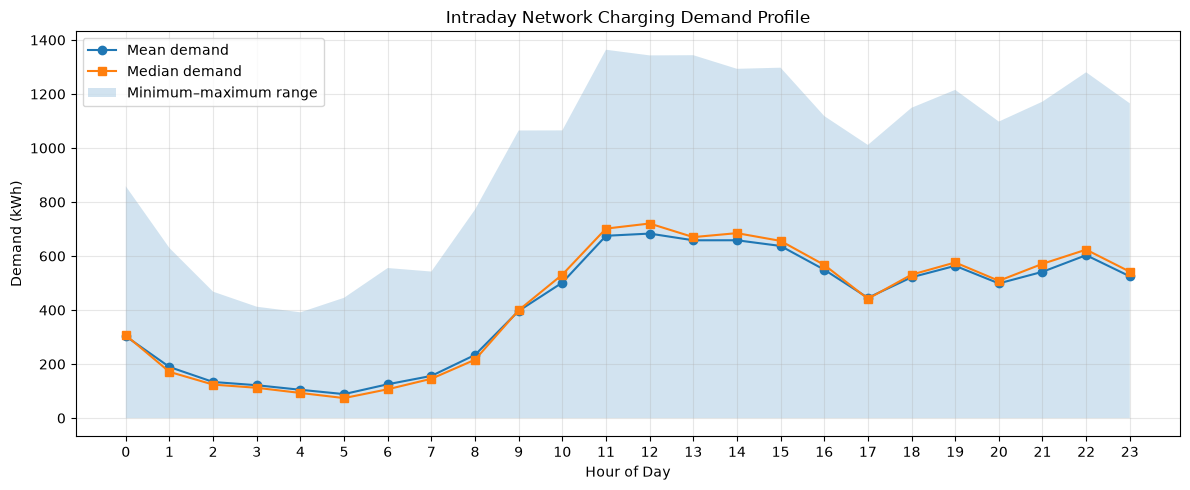

In [78]:
# Calculate network demand statistics by hour of day
intraday_summary = (
    network_demand
    .groupby(network_demand.index.hour)
    .agg(
        Mean="mean",
        Median="median",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max",
    )
)

intraday_summary.index.name = "Hour of Day"
display(intraday_summary.round(2))

# Visualise the typical intraday demand profile
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    intraday_summary.index,
    intraday_summary["Mean"],
    marker="o",
    label="Mean demand",
)
ax.plot(
    intraday_summary.index,
    intraday_summary["Median"],
    marker="s",
    label="Median demand",
)

ax.fill_between(
    intraday_summary.index,
    intraday_summary["Minimum"],
    intraday_summary["Maximum"],
    alpha=0.2,
    label="Minimum–maximum range",
)

ax.set_title("Intraday Network Charging Demand Profile")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Demand (kWh)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Intraday Seasonality Analysis

The hourly demand profile shows a clear daily cycle:

- Demand is highest during the middle of the day, increasing rapidly from 08:00 and reaching its mean peak at **12:00 (683.16 kWh)**.
- Demand remains high from **11:00 to 15:00**, indicating a sustained midday peak rather than a single-hour spike.
- A secondary evening peak occurs around **19:00 (563.78 kWh)** and **22:00 (603.21 kWh)**.
- Overnight demand declines steadily after midnight, reaching its lowest mean at **05:00 (88.78 kWh)**.
- Demand begins increasing again from 06:00, with a pronounced morning ramp between 08:00 and 11:00.

The median follows a similar pattern, peaking at **12:00 (720.48 kWh)**. At several peak hours, the median exceeds the mean, suggesting that occasional low-demand periods reduce the average. The minimum demand is zero for every hour, indicating that some days contain no recorded charging activity during each hourly interval.

Variability is greatest during high-demand periods. The largest standard deviation occurs at **11:00 (306.79 kWh)**, followed by 12:00 and 13:00. The maximum hourly value of **1,363.87 kWh** occurs at 11:00, demonstrating substantial variation around the typical demand profile.

These results indicate that day-ahead forecasting models should include hour-of-day effects and distinguish between overnight, morning, midday, and evening demand regimes. Peak-period forecasts should also account for greater variance and the possibility of occasional zero-demand observations.

##### Weekly and Calendar Seasonality

,Mean hourly demand,Median hourly demand,Standard deviation,Total demand
Monday,411.51,380.64,294.88,1027121.00
Tuesday,405.10,376.94,291.76,1012351.97
Wednesday,404.84,372.75,288.66,1020199.12
Thursday,408.90,378.87,290.47,1030420.84
Friday,425.65,392.24,302.42,1072636.73
Saturday,423.78,401.58,296.00,1057766.78
Sunday,412.38,390.19,287.66,1029298.13


,Mean hourly demand,Median hourly demand,Standard deviation,Total demand,Observations
Weekend,,,,,
Weekday,411.21,380.78,293.73,5162729.66,12555
Weekend,418.08,395.72,291.89,2087064.91,4992


,Mean hourly demand,Median hourly demand,Standard deviation,Total demand
January,256.32,197.09,216.64,381411.39
February,139.26,61.36,162.43,190508.73
March,238.00,177.76,204.66,354149.11
April,331.33,316.68,223.11,477110.89
May,394.20,416.64,237.38,586570.46
June,441.62,446.27,264.85,635933.79
July,516.99,532.12,296.82,769275.96
August,529.04,564.08,298.19,787209.37
September,525.56,552.00,292.38,756808.39
October,519.67,532.06,290.49,773268.04


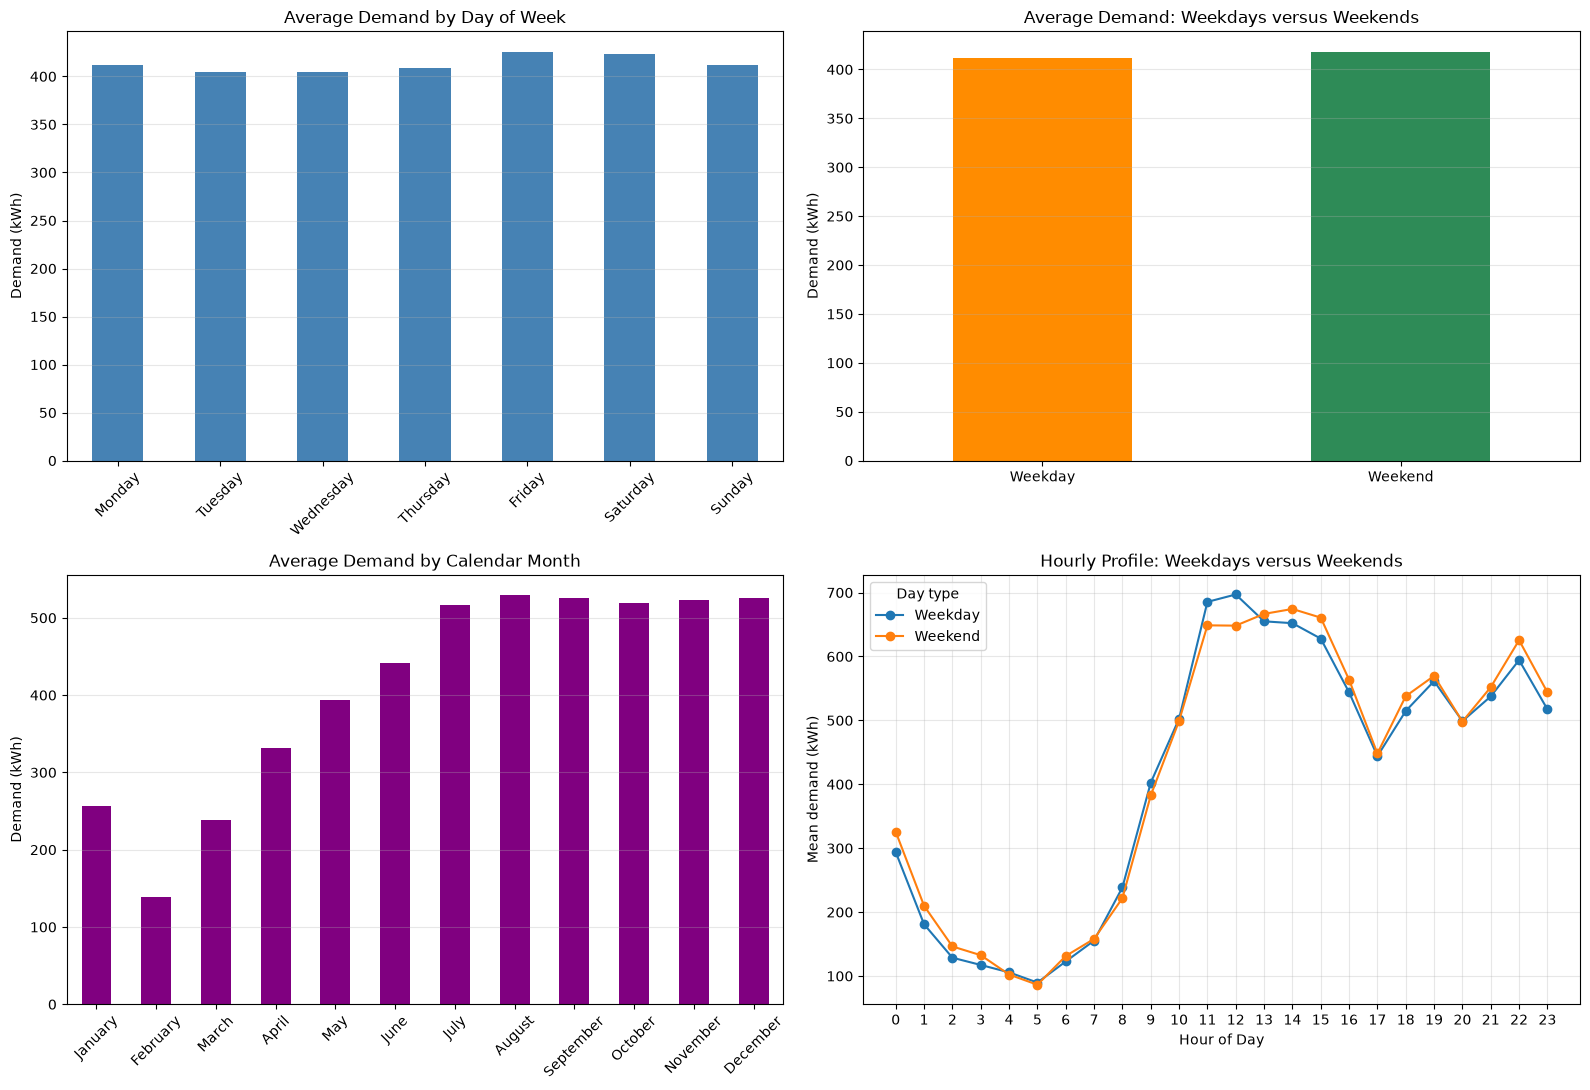

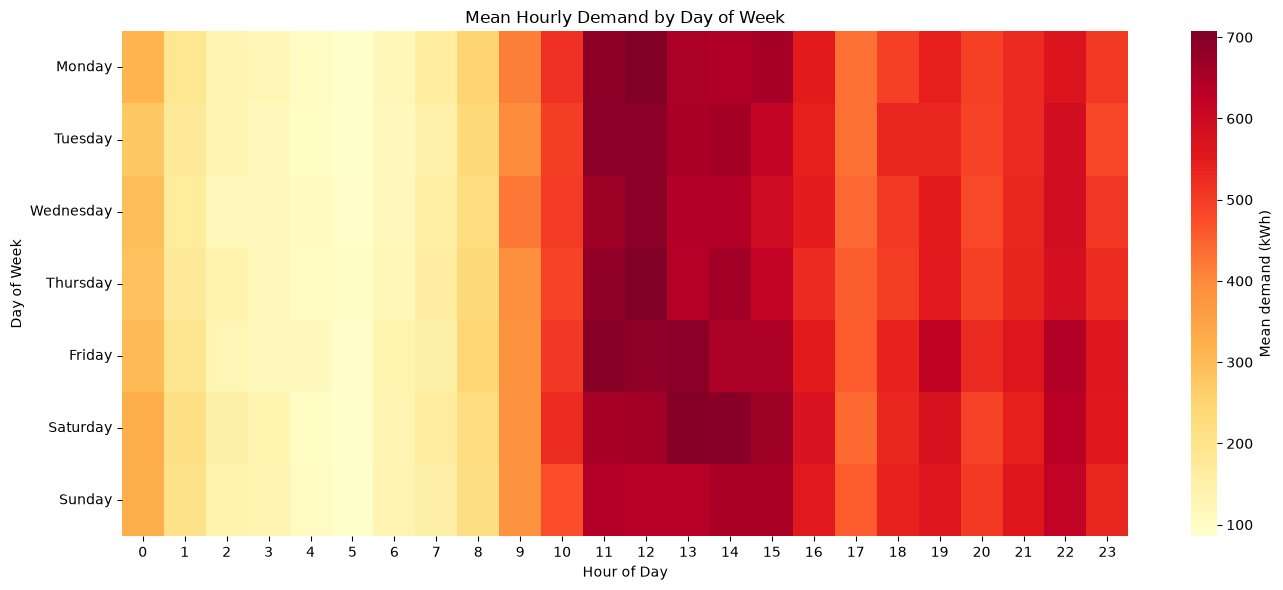

Holiday-specific analysis is unavailable because the dataset does not contain a holiday or public-holiday indicator.


In [79]:
# Add calendar attributes for seasonal comparisons
calendar_demand = network_demand.to_frame("Demand")
calendar_demand["Day"] = calendar_demand.index.day_name()
calendar_demand["Day_Number"] = calendar_demand.index.dayofweek
calendar_demand["Weekend"] = np.where(
    calendar_demand["Day_Number"] >= 5, "Weekend", "Weekday"
)
calendar_demand["Month"] = calendar_demand.index.month
calendar_demand["Month_Name"] = calendar_demand.index.month_name()
calendar_demand["Hour"] = calendar_demand.index.hour

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
month_order = list(range(1, 13))

# Demand summary by day of week
day_of_week_summary = (
    calendar_demand.groupby("Day_Number")["Demand"]
    .agg(["mean", "median", "std", "sum"])
    .reindex(range(7))
)
day_of_week_summary.index = day_order
day_of_week_summary.columns = [
    "Mean hourly demand", "Median hourly demand",
    "Standard deviation", "Total demand"
]

# Weekday versus weekend comparison
weekday_weekend_summary = (
    calendar_demand.groupby("Weekend")["Demand"]
    .agg(["mean", "median", "std", "sum", "count"])
    .reindex(["Weekday", "Weekend"])
)
weekday_weekend_summary.columns = [
    "Mean hourly demand", "Median hourly demand",
    "Standard deviation", "Total demand", "Observations"
]

# Demand by calendar month, pooled across years
monthly_seasonality = (
    calendar_demand.groupby("Month")["Demand"]
    .agg(["mean", "median", "std", "sum"])
    .reindex(month_order)
)
monthly_seasonality.index = [
    pd.Timestamp(2000, month, 1).month_name()
    for month in month_order
]
monthly_seasonality.columns = [
    "Mean hourly demand", "Median hourly demand",
    "Standard deviation", "Total demand"
]

display(day_of_week_summary.round(2))
display(weekday_weekend_summary.round(2))
display(monthly_seasonality.round(2))

# Average hourly profile by day type
day_type_hourly = (
    calendar_demand.groupby(["Weekend", "Hour"])["Demand"]
    .mean()
    .unstack("Weekend")
    .reindex(index=range(24))
)

# Average hourly profile by day of week
day_hourly_profile = (
    calendar_demand.groupby(["Day_Number", "Hour"])["Demand"]
    .mean()
    .unstack("Day_Number")
    .reindex(index=range(24), columns=range(7))
)
day_hourly_profile.columns = day_order

# Visualisations
fig, axes_calendar = plt.subplots(2, 2, figsize=(16, 11))

day_of_week_summary["Mean hourly demand"].plot(
    kind="bar", ax=axes_calendar[0, 0], color="steelblue"
)
axes_calendar[0, 0].set_title("Average Demand by Day of Week")
axes_calendar[0, 0].set_ylabel("Demand (kWh)")
axes_calendar[0, 0].set_xlabel("")
axes_calendar[0, 0].tick_params(axis="x", rotation=45)

weekday_weekend_summary["Mean hourly demand"].plot(
    kind="bar", ax=axes_calendar[0, 1], color=["darkorange", "seagreen"]
)
axes_calendar[0, 1].set_title("Average Demand: Weekdays versus Weekends")
axes_calendar[0, 1].set_ylabel("Demand (kWh)")
axes_calendar[0, 1].set_xlabel("")
axes_calendar[0, 1].tick_params(axis="x", rotation=0)

monthly_seasonality["Mean hourly demand"].plot(
    kind="bar", ax=axes_calendar[1, 0], color="purple"
)
axes_calendar[1, 0].set_title("Average Demand by Calendar Month")
axes_calendar[1, 0].set_ylabel("Demand (kWh)")
axes_calendar[1, 0].set_xlabel("")
axes_calendar[1, 0].tick_params(axis="x", rotation=45)

day_type_hourly.plot(
    ax=axes_calendar[1, 1], marker="o"
)
axes_calendar[1, 1].set_title("Hourly Profile: Weekdays versus Weekends")
axes_calendar[1, 1].set_xlabel("Hour of Day")
axes_calendar[1, 1].set_ylabel("Mean demand (kWh)")
axes_calendar[1, 1].set_xticks(range(24))
axes_calendar[1, 1].grid(alpha=0.3)
axes_calendar[1, 1].legend(title="Day type")

for calendar_axis in axes_calendar.flat:
    calendar_axis.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Day-of-week and hour heatmap
plt.figure(figsize=(14, 6))
sns.heatmap(
    day_hourly_profile.T,
    cmap="YlOrRd",
    annot=False,
    cbar_kws={"label": "Mean demand (kWh)"}
)
plt.title("Mean Hourly Demand by Day of Week")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

print(
    "Holiday-specific analysis is unavailable because the dataset does not "
    "contain a holiday or public-holiday indicator."
)

##### Weekly and Calendar Seasonality Findings

- **Demand is relatively stable across the week**, with mean hourly demand ranging from **404.84 kWh on Wednesday** to **425.65 kWh on Friday**.
- **Friday has the highest average and total demand**, while Tuesday and Wednesday have the lowest average hourly demand.
- **Weekend demand is slightly higher than weekday demand**: 418.08 kWh versus 411.21 kWh per hour. This difference is modest, indicating that charging activity is not strongly restricted to working days.
- Weekend observations have a slightly lower standard deviation than weekdays, suggesting marginally more consistent demand.
- **Strong monthly seasonality is evident.** Average demand increases from February through August, reaching a maximum of **529.04 kWh in August**, before remaining high through December.
- **February records the lowest demand**, at 139.26 kWh per hour. This substantial reduction may reflect operational disruptions, data-quality effects, or unusual external conditions rather than ordinary seasonal behaviour.
- Demand variability generally increases during higher-demand months. The largest standard deviation occurs in **December (314.39 kWh)**, while February has the lowest variability.
- In several months, the median exceeds the mean, particularly from May onward. This suggests that occasional low-demand periods reduce the mean, while typical hourly demand remains comparatively high.
- Monthly totals should be interpreted alongside the number of observations because calendar months contain different numbers of days. Overall, the results indicate a pronounced seasonal increase in charging demand from spring into the second half of the year.

These findings support including **day-of-week, weekend, month, and trend features** in the day-ahead forecasting models. Special attention should be given to February and other periods with possible structural disruptions.

#### Changes in Demand Patterns

C:\Users\Rodrigo\AppData\Local\Temp\ipykernel_34336\2256555473.py:40: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_pattern_summary.round(2))


,Average_Hourly_Demand,Peak_Hourly_Demand,Hourly_Standard_Deviation,Total_Demand,Observed_Hours,Peak_Demand_Timestamp,Peak_Demand_Hour,Average_Daily_Demand,Peak_Daily_Demand,Daily_Standard_Deviation,Total_Daily_Demand,Observed_Days
2020-01,140.34,569.47,117.61,104416.29,744,2020-01-18 12:00:00,12,3368.27,5228.57,1220.14,104416.29,31
2020-02,29.68,168.88,38.17,20660.50,696,2020-02-29 16:00:00,16,712.43,1598.51,371.02,20660.50,29
2020-03,136.84,685.70,128.31,101805.83,744,2020-03-27 12:00:00,12,3284.06,6581.55,1564.17,101805.83,31
2020-04,261.95,826.68,174.89,188604.52,720,2020-04-30 12:00:00,12,6286.82,8751.44,879.98,188604.52,30
2020-05,349.05,1032.80,205.52,259693.93,744,2020-05-03 15:00:00,15,8377.22,10327.89,863.09,259693.93,31
2020-06,430.17,1280.45,264.16,309722.95,720,2020-06-27 22:00:00,22,10324.10,12648.54,1081.12,309722.95,30
2020-07,495.84,1270.59,274.07,368903.69,744,2020-07-05 22:00:00,22,11900.12,13621.05,912.08,368903.69,31
2020-08,542.94,1260.87,296.10,403949.16,744,2020-08-14 22:00:00,22,13030.62,14910.37,1049.70,403949.16,31
2020-09,452.63,1169.50,258.58,325893.82,720,2020-09-07 11:00:00,11,10863.13,12314.89,725.28,325893.82,30
2020-10,439.55,1026.64,248.73,327028.84,744,2020-10-05 13:00:00,13,10549.32,13536.26,1023.23,327028.84,31


,Average_Hourly_Demand,Peak_Hourly_Demand,Hourly_Standard_Deviation,Total_Demand,Average_Daily_Demand,Peak_Daily_Demand,Daily_Standard_Deviation
Period,,,,,,,
2020-H1,225.48,1280.45,217.97,984904.02,5411.56,12648.54,3430.73
2020-H2,469.78,1270.59,270.78,2074538.31,11274.66,14910.37,1372.05
2021-H1,377.71,1130.94,241.81,1640780.35,9065.08,13341.33,1912.64
2021-H2,577.24,1363.87,312.38,2549109.19,13853.85,17180.71,1475.23


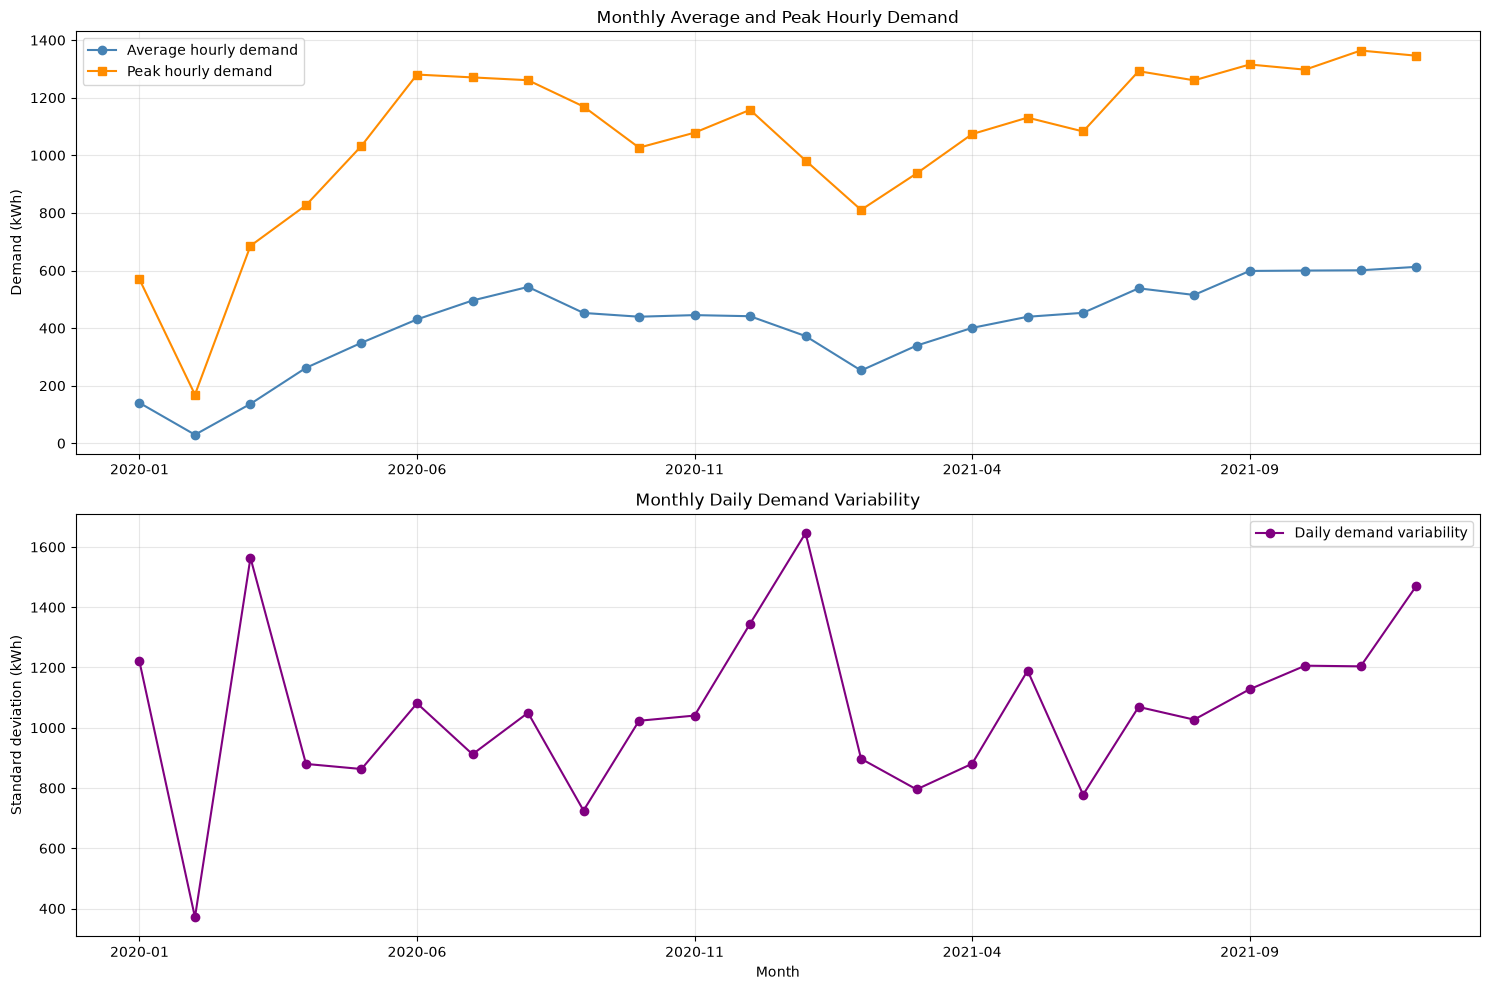

In [80]:
# Compare demand patterns across calendar months using complete days only
analysis_demand = network_demand.loc["2020-01-01":].copy()
analysis_daily = daily_network.loc["2020-01-01":].copy()

# Monthly summary of hourly demand
monthly_pattern_summary = (
    analysis_demand.groupby(analysis_demand.index.to_period("M"))
    .agg(
        Average_Hourly_Demand="mean",
        Peak_Hourly_Demand="max",
        Hourly_Standard_Deviation="std",
        Total_Demand="sum",
        Observed_Hours="count",
    )
)

# Timestamp and hour of each monthly hourly peak
monthly_peak_rows = analysis_demand.groupby(
    analysis_demand.index.to_period("M")
).idxmax()

monthly_pattern_summary["Peak_Demand_Timestamp"] = monthly_peak_rows
monthly_pattern_summary["Peak_Demand_Hour"] = monthly_peak_rows.dt.hour

# Daily demand statistics by month
daily_monthly_summary = (
    analysis_daily.groupby(analysis_daily.index.to_period("M"))
    .agg(
        Average_Daily_Demand="mean",
        Peak_Daily_Demand="max",
        Daily_Standard_Deviation="std",
        Total_Daily_Demand="sum",
        Observed_Days="count",
    )
)

monthly_pattern_summary = monthly_pattern_summary.join(daily_monthly_summary)

monthly_pattern_summary.index = monthly_pattern_summary.index.astype(str)
display(monthly_pattern_summary.round(2))

# Compare half-year periods
half_year_demand = analysis_demand.to_frame("Demand")
half_year_demand["Period"] = (
    half_year_demand.index.year.astype(str)
    + "-H"
    + ((half_year_demand.index.month - 1) // 6 + 1).astype(str)
)

half_year_summary = (
    half_year_demand.groupby("Period")["Demand"]
    .agg(
        Average_Hourly_Demand="mean",
        Peak_Hourly_Demand="max",
        Hourly_Standard_Deviation="std",
        Total_Demand="sum",
    )
)

half_year_daily = analysis_daily.to_frame("Demand")
half_year_daily["Period"] = (
    half_year_daily.index.year.astype(str)
    + "-H"
    + ((half_year_daily.index.month - 1) // 6 + 1).astype(str)
)

half_year_summary = half_year_summary.join(
    half_year_daily.groupby("Period")["Demand"].agg(
        Average_Daily_Demand="mean",
        Peak_Daily_Demand="max",
        Daily_Standard_Deviation="std",
    )
)

display(half_year_summary.round(2))

# Visualise changes in demand level and variability
fig, axes_patterns = plt.subplots(2, 1, figsize=(15, 10))

monthly_pattern_summary["Average_Hourly_Demand"].plot(
    ax=axes_patterns[0],
    marker="o",
    color="steelblue",
    label="Average hourly demand",
)
monthly_pattern_summary["Peak_Hourly_Demand"].plot(
    ax=axes_patterns[0],
    marker="s",
    color="darkorange",
    label="Peak hourly demand",
)
axes_patterns[0].set_title("Monthly Average and Peak Hourly Demand")
axes_patterns[0].set_ylabel("Demand (kWh)")
axes_patterns[0].grid(alpha=0.3)
axes_patterns[0].legend()

monthly_pattern_summary["Daily_Standard_Deviation"].plot(
    ax=axes_patterns[1],
    marker="o",
    color="purple",
    label="Daily demand variability",
)
axes_patterns[1].set_title("Monthly Daily Demand Variability")
axes_patterns[1].set_ylabel("Standard deviation (kWh)")
axes_patterns[1].set_xlabel("Month")
axes_patterns[1].grid(alpha=0.3)
axes_patterns[1].legend()

plt.tight_layout()
plt.show()

## Changes in Demand Patterns Findings

- **Demand increased substantially over the observation period.** Average hourly demand rose from **140.34 kWh in January 2020** to **612.64 kWh in December 2021**. Average daily demand increased from **3,368.27 kWh** to **14,703.32 kWh**.
- **The strongest growth occurred during 2020.** Average hourly demand increased from **225.48 kWh in 2020-H1** to **469.78 kWh in 2020-H2**, more than doubling.
- Demand continued to expand in 2021. Average hourly demand rose from **377.71 kWh in 2021-H1** to **577.24 kWh in 2021-H2**, an increase of approximately **53%**.
- Comparing the second halves of each year, average hourly demand increased from **469.78 kWh in 2020-H2** to **577.24 kWh in 2021-H2**, representing growth of approximately **23%**.
- **February is a major structural low-demand period** in both years, particularly February 2020, when average hourly demand fell to only **29.68 kWh**. This likely reflects an operational disruption or abnormal data period rather than normal seasonality.
- Peak demand also strengthened over time. The highest hourly value was **1,363.87 kWh on 24 November 2021 at 11:00**, while the highest daily value was **17,180.71 kWh on 1 October 2021**.
- Hourly variability generally increased with demand. The hourly standard deviation reached **333.42 kWh in December 2021**, compared with **117.61 kWh in January 2020**, indicating greater absolute forecasting uncertainty during later high-demand periods.
- Monthly peaks most commonly occurred between **11:00 and 15:00**, although several summer and winter peaks occurred around **22:00** or during the evening. This suggests that peak timing is not completely stable across months.
- Daily variability was exceptionally high in **2020-H1**, largely because this period includes the severe February decline. Afterward, daily standard deviation was lower and more stable, although it increased again during the high-demand periods of late 2021.
- All full calendar months contain the expected number of hourly observations, and monthly total demand is consistent with the corresponding daily totals.

These results indicate a combination of **network expansion, strong seasonal effects, changing peak timing, and increasing demand variance**. Forecasting models should therefore include trend features, month and hour-of-day effects, and mechanisms capable of handling structural disruptions such as the February periods.

#### District-Level Comparison

C:\Users\Rodrigo\AppData\Local\Temp\ipykernel_34336\3108779952.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(district_summary.round(2))


,Total demand (kWh),Average hourly demand (kWh),Share of network demand (%),Peak hourly demand (kWh),Peak timestamp,Peak hour,Hourly standard deviation,Coefficient of variation
Nanhu,1249915.68,71.24,17.24,551.50,2021-10-29 11:00:00,11,70.97,1.00
Tongxiang,3819981.38,217.74,52.69,845.30,2021-11-26 18:00:00,18,164.26,0.75
Xiuzhou,2179434.81,124.23,30.06,632.32,2020-06-27 22:00:00,22,106.76,0.86


,Nanhu,Tongxiang,Xiuzhou
Hour of day,,,
0,64.85,146.77,91.25
1,45.17,91.13,52.88
2,28.96,66.63,38.09
3,25.51,67.72,28.44
4,18.94,54.35,31.49
5,21.38,38.45,28.95
6,27.13,62.92,35.18
7,23.51,84.90,47.76
8,34.13,134.49,65.31


Nanhu  Tongxiang  Xiuzhou
Day type Hour                            
Weekday  0      61.73     142.94    89.15
         1      43.09      86.34    51.53
         2      26.24      64.64    37.79
         3      24.02      66.59    26.71
         4      18.27      53.67    33.79
         5      21.29      38.68    29.79
         6      26.56      61.48    34.75
         7      22.51      85.70    47.19
         8      35.47     137.74    65.50
         9      65.58     230.59   106.29
         10     90.52     266.71   145.41
         11    164.21     300.55   220.69
         12    141.73     333.87   221.43
         13    121.49     337.75   195.78
         14    117.89     339.22   195.01
         15    111.31     325.71   190.96
         16     85.87     273.57   184.51
         17     65.25     223.16   155.65
         18     59.35     294.80   160.59
         19     67.89     334.65   158.91
         20     56.82     298.13   143.93
         21     74.17     310.86   153.45
         22    111.79     311.64   171.88
         23     93.07     265.48   159.20
Weekend  0      72.70     156.40    96.52
         1      50.39     103.17    56.28
         2      35.78      71.65    38.85
         3      29.28      70.55    32.78
         4      20.62      56.06    25.68
         5      21.62      37.87    26.84
         6      28.56      66.54    36.27
         7      26.04      82.86    49.20
         8      30.77     126.30    64.82
         9      55.61     224.50   102.41
         10     85.05     274.42   139.80
         11    154.59     287.49   206.66
         12    120.42     322.81   205.04
         13    113.91     353.59   199.15
         14    123.03     351.40   199.93
         15    116.50     339.18   205.12
         16     90.95     289.35   183.27
         17     63.11     231.51   153.67
         18     65.31     303.71   168.86
         19     73.38     336.30   159.98
         20     51.95     303.30   142.93
         21     81.51     323.17   147.30
         22    113.88     336.71   174.89
         23     94.41     280.47   169.08

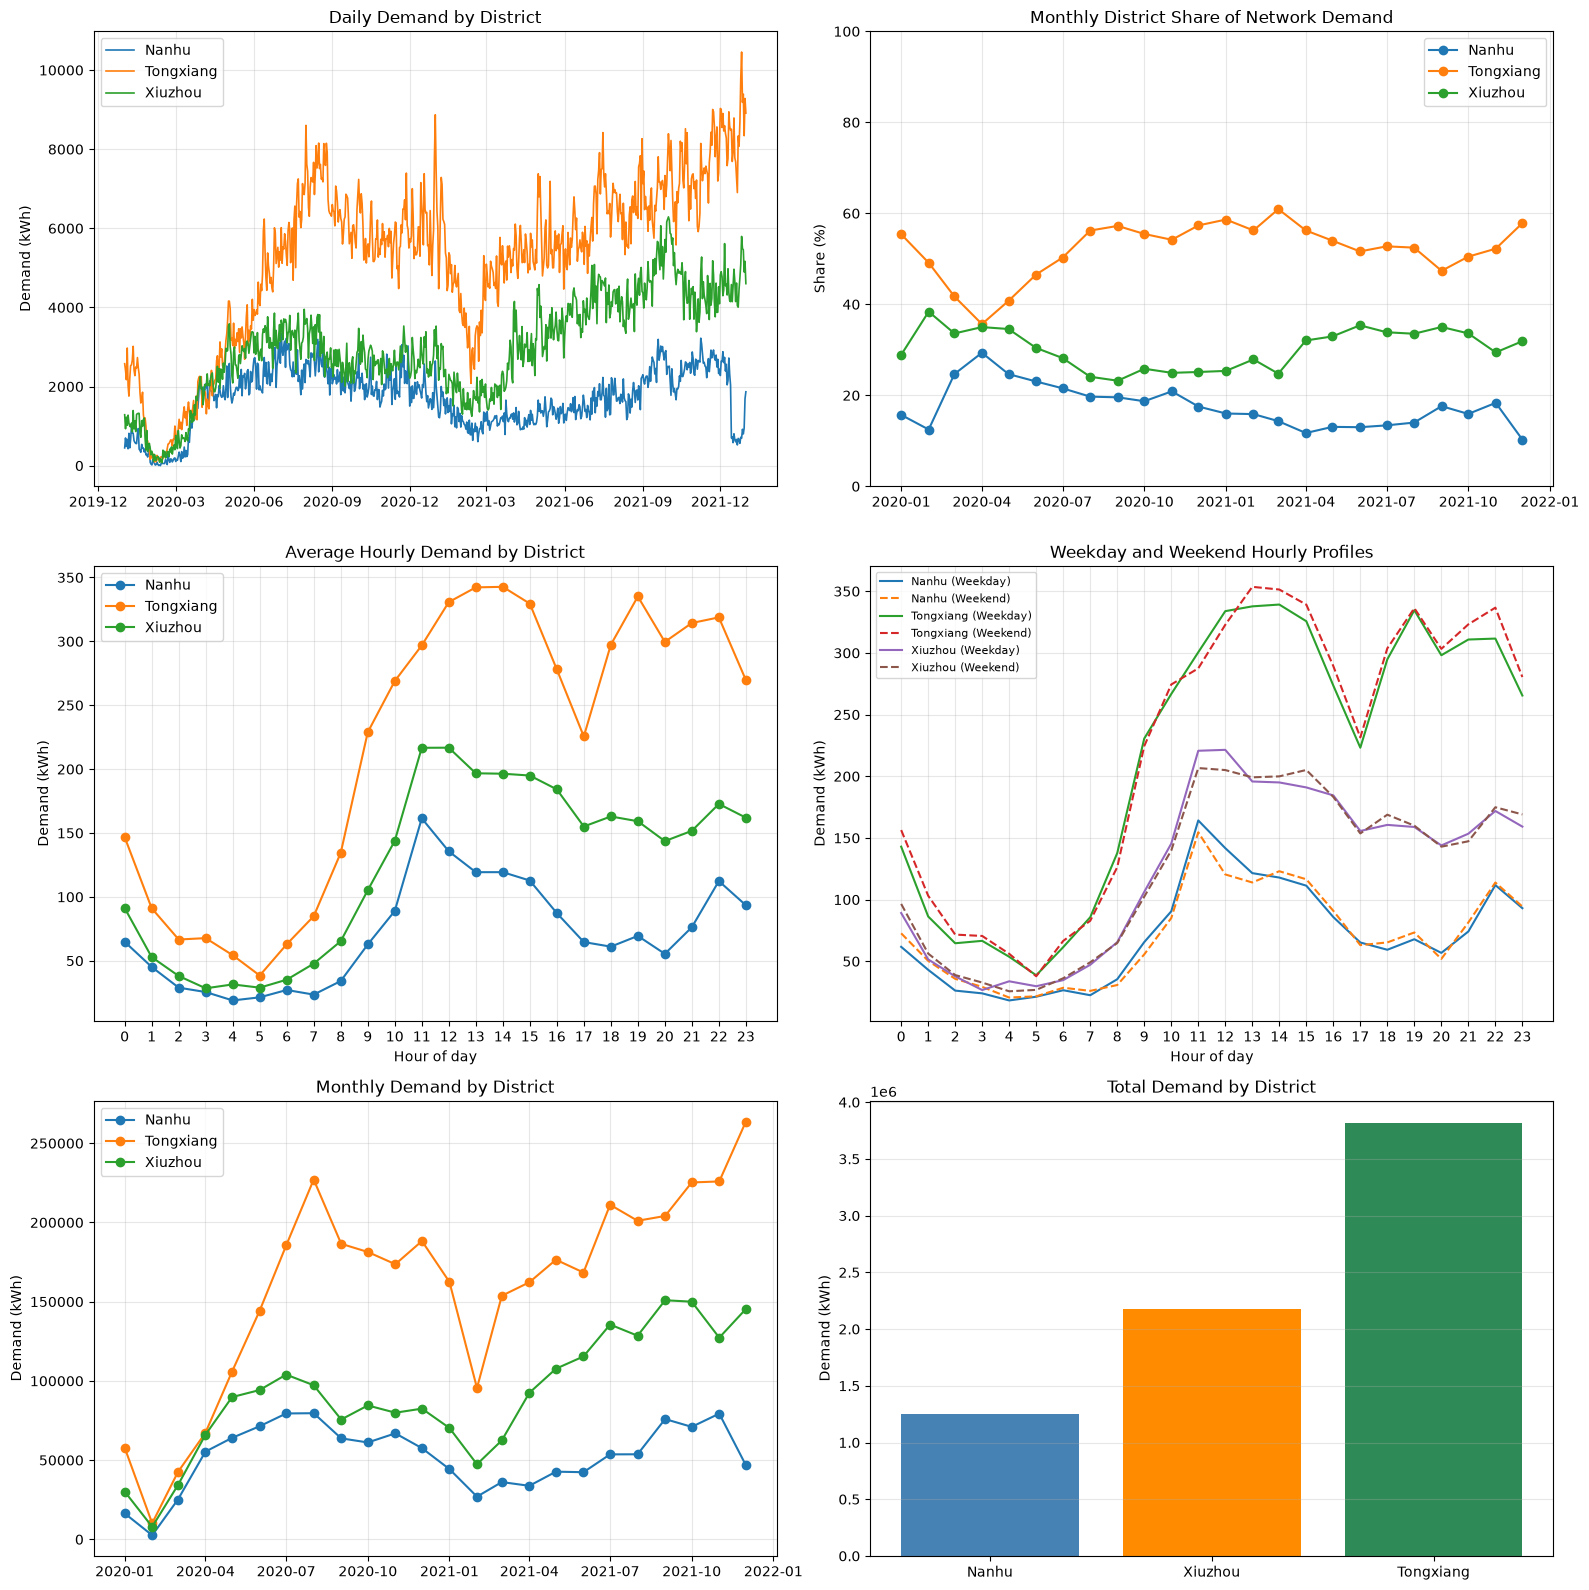

In [82]:
# District-level demand comparison
districts = ["Nanhu", "Tongxiang", "Xiuzhou"]

# Use the common observation period and exclude the partial first day
district_hourly = hourly_demand[districts].loc["2020-01-01":].copy()
district_daily = district_hourly.resample("D").sum()
district_monthly = district_hourly.resample("MS").sum()

# Overall demand, contribution, peak, and variability
district_summary = pd.DataFrame(index=districts)
district_summary["Total demand (kWh)"] = district_hourly.sum()
district_summary["Average hourly demand (kWh)"] = district_hourly.mean()
district_summary["Share of network demand (%)"] = (
    district_summary["Total demand (kWh)"]
    / district_hourly.sum().sum()
    * 100
)
district_summary["Peak hourly demand (kWh)"] = district_hourly.max()
district_summary["Peak timestamp"] = district_hourly.idxmax()
district_summary["Peak hour"] = district_summary["Peak timestamp"].dt.hour
district_summary["Hourly standard deviation"] = district_hourly.std()
district_summary["Coefficient of variation"] = (
    district_summary["Hourly standard deviation"]
    / district_summary["Average hourly demand (kWh)"]
)

display(district_summary.round(2))

# Average hourly profile
district_hourly_profile = (
    district_hourly.groupby(district_hourly.index.hour)
    .mean()
)
district_hourly_profile.index.name = "Hour of day"

# Weekday/weekend profiles
district_calendar = district_hourly.copy()
district_calendar["Day type"] = np.where(
    district_calendar.index.dayofweek >= 5,
    "Weekend",
    "Weekday",
)

district_day_type_profile = (
    district_calendar
    .groupby(["Day type", district_calendar.index.hour])[districts]
    .mean()
    .rename_axis(index=["Day type", "Hour"])
)

# Monthly demand trends
district_monthly_share = district_monthly.div(
    district_monthly.sum(axis=1),
    axis=0
) * 100

# Display profiles
display(district_hourly_profile.round(2))
display(district_day_type_profile.round(2))

# Visualisations
fig, axes_district = plt.subplots(3, 2, figsize=(16, 16))

# 1. Total daily demand over time [0, 0]
for district in districts:
    axes_district[0, 0].plot(
        district_daily.index,
        district_daily[district],
        linewidth=1.2,
        label=district,
    )
axes_district[0, 0].set_title("Daily Demand by District")
axes_district[0, 0].set_ylabel("Demand (kWh)")
axes_district[0, 0].legend()
axes_district[0, 0].grid(alpha=0.3)

# 2. Monthly demand shares [0, 1]
for district in districts:
    axes_district[0, 1].plot(
        district_monthly_share.index,
        district_monthly_share[district],
        marker="o",
        linewidth=1.5,
        label=district,
    )
axes_district[0, 1].set_title("Monthly District Share of Network Demand")
axes_district[0, 1].set_ylabel("Share (%)")
axes_district[0, 1].set_ylim(0, 100)
axes_district[0, 1].legend()
axes_district[0, 1].grid(alpha=0.3)

# 3. Average hourly profiles [1, 0] (Eixo X = Horas 0-23)
for district in districts:
    axes_district[1, 0].plot(
        district_hourly_profile.index,
        district_hourly_profile[district],
        marker="o",
        linewidth=1.5,
        label=district,
    )
axes_district[1, 0].set_title("Average Hourly Demand by District")
axes_district[1, 0].set_xlabel("Hour of day")
axes_district[1, 0].set_ylabel("Demand (kWh)")
axes_district[1, 0].set_xticks(range(24))
axes_district[1, 0].legend()
axes_district[1, 0].grid(alpha=0.3)

# 4. Weekday/weekend profiles [1, 1] (Eixo X = Horas 0-23)
for district in districts:
    for day_type, style in zip(["Weekday", "Weekend"], ["-", "--"]):
        profile = district_day_type_profile.loc[day_type, district]
        axes_district[1, 1].plot(
            profile.index,
            profile.values,
            linestyle=style,
            label=f"{district} ({day_type})",
        )
axes_district[1, 1].set_title("Weekday and Weekend Hourly Profiles")
axes_district[1, 1].set_xlabel("Hour of day")
axes_district[1, 1].set_ylabel("Demand (kWh)")
axes_district[1, 1].set_xticks(range(24))
axes_district[1, 1].legend(fontsize=8)
axes_district[1, 1].grid(alpha=0.3)

# 5. Monthly demand [2, 0]
for district in districts:
    axes_district[2, 0].plot(
        district_monthly.index,
        district_monthly[district],
        marker="o",
        linewidth=1.5,
        label=district,
    )
axes_district[2, 0].set_title("Monthly Demand by District")
axes_district[2, 0].set_ylabel("Demand (kWh)")
axes_district[2, 0].legend()
axes_district[2, 0].grid(alpha=0.3)

# 6. Total demand bar chart [2, 1] (Eixo X = Nomes dos distritos)
sorted_totals = district_summary["Total demand (kWh)"].sort_values()
axes_district[2, 1].bar(
    sorted_totals.index,
    sorted_totals.values,
    color=["steelblue", "darkorange", "seagreen"],
)
axes_district[2, 1].set_title("Total Demand by District")
axes_district[2, 1].set_ylabel("Demand (kWh)")
axes_district[2, 1].grid(axis="y", alpha=0.3)

# Formatar datas APENAS nos 3 gráficos temporais
date_axes = [axes_district[0, 0], axes_district[0, 1], axes_district[2, 0]]
for axis in date_axes:
    axis.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.tight_layout()
plt.show()

## District-Level Demand Findings

- **Tongxiang is the dominant district**, contributing **52.69%** of total network demand and averaging **217.74 kWh per hour**. Xiuzhou contributes **30.06%**, while Nanhu contributes **17.24%**.
- Tongxiang also records the highest hourly peak at **845.30 kWh** on **26 November 2021 at 18:00**. Xiuzhou peaks at **632.32 kWh**, while Nanhu peaks at **551.50 kWh**.
- **Nanhu has the greatest relative variability**, with a coefficient of variation of approximately **1.00**. Its demand is therefore less stable relative to its lower average level. Tongxiang has the lowest relative variability at **0.75**.
- All districts exhibit a clear intraday pattern. Demand is lowest during the early morning, generally around **04:00–06:00**, and increases substantially after **09:00**.
- Tongxiang reaches its typical hourly maximum at approximately **14:00** with **342.69 kWh**, while Xiuzhou peaks around **12:00** at **216.77 kWh**. Nanhu has a less stable profile, with its highest average at **11:00** at **161.47 kWh**.
- Tongxiang maintains the highest demand throughout nearly every hour, making its behaviour especially important for network-level forecasts and capacity planning.
- Differences between weekdays and weekends are relatively small. Weekend demand is often slightly higher overnight and during the evening, while weekday demand is marginally higher around several midday hours.
- Xiuzhou and Tongxiang show similar daily profiles, with strong daytime and evening activity. Nanhu has lower demand overall but displays comparatively greater proportional fluctuations.
- District peak times are not identical: Tongxiang peaks in the evening, Xiuzhou peaks late at night, and Nanhu peaks around midday. Consequently, district-specific forecasting is preferable to assuming a common network-wide peak pattern.

These results indicate that forecasting models should include **district-specific effects, hour-of-day features, weekday/weekend indicators, and measures of changing demand variability**. Operational planning should prioritise Tongxiang because of its dominant demand share, while Nanhu requires attention because of its higher relative uncertainty.

### Overall Findings

- **Dominant temporal patterns:** Demand follows a strong intraday cycle. It is lowest during the early morning, particularly around **04:00–06:00**, rises sharply from approximately **08:00**, and remains highest between **11:00 and 15:00**. A secondary evening increase occurs around **18:00–22:00**.

- **Typical daily and weekly cycle:** Network demand reaches its average hourly maximum at **12:00 (683.16 kWh)**, while the lowest average occurs at **05:00 (88.78 kWh)**. Weekend demand is slightly higher than weekday demand (**418.08 kWh versus 411.21 kWh per hour**), indicating that charging is distributed across the entire week rather than being strongly concentrated on working days.

- **Long-term growth:** Demand increased substantially over the observation period. Average hourly demand rose from **140.34 kWh in January 2020** to **612.64 kWh in December 2021**. Average daily demand also increased from **3,368.27 kWh** to **14,703.32 kWh**, indicating substantial network expansion and increased utilisation.

- **Periods of changed behaviour:** February shows unusually low demand in both years, particularly **February 2020**, when average hourly demand fell to **29.68 kWh**. This likely represents an operational disruption, abnormal external conditions, or a data-quality issue rather than normal seasonality. Demand and absolute variability increased during the later high-demand periods, especially in the second half of 2021.

- **District contributions:** **Tongxiang** is the dominant district, contributing **52.69%** of total demand. **Xiuzhou** contributes **30.06%**, and **Nanhu** contributes **17.24%**. Tongxiang should therefore receive the greatest emphasis in network-level forecasting and capacity planning.

- **District-specific profiles:** The districts share a general daytime demand cycle, but their peaks are not identical. Tongxiang typically peaks around **14:00**, Xiuzhou around **12:00**, and Nanhu around **11:00**. Observed absolute peaks also differ: Tongxiang peaks at **18:00**, Xiuzhou at **22:00**, and Nanhu at **11:00**. Nanhu has the greatest relative variability, with a coefficient of variation of approximately **1.00**, compared with **0.75** for Tongxiang.

- **Forecasting implications:** Day-ahead models should include hour-of-day, day-of-week, weekend, month, trend, and district-specific features. Models should also account for growth, changing variance, zero-demand hours, and abnormal February periods. District-level forecasts are preferable to assuming a common demand profile, while network forecasts should incorporate the dominant contribution and temporal behaviour of Tongxiang.

- **Capacity-planning implications:** Capacity should be assessed for the sustained midday peak as well as the secondary evening peak. Tongxiang requires the largest capacity allocation, while Nanhu requires greater uncertainty margins because of its higher relative variability. Peak timing should be monitored separately by district to avoid underestimating geographically distinct local requirements.

## Operational forecasting formulation 

### Forecast Issuance Schedule

### Forecasting Protocol Justification

The forecasting protocol defines a realistic day-ahead forecasting scenario in which predictions are issued at **00:00** for the next calendar day.

- The forecast horizon is **24 hourly observations**, representing the complete day ahead.
- Only demand information available up to **23:00 on the previous day** is used, preventing data leakage.
- A **direct multi-step forecasting strategy** is adopted, with one model trained for each horizon from 1 to 24 hours ahead. This allows each model to learn horizon-specific demand patterns.
- Future actual demand is unavailable at the time of forecast issuance and is therefore excluded from the predictors.
- Future observed weather is also unavailable. Weather variables may only be included if reliable weather forecasts are available; otherwise, they are excluded to maintain a realistic evaluation.
- The target variable is hourly charging demand at the network and district levels.

In [84]:
# Forecasting protocol
forecast_config = {
    "issuance_time": "00:00",
    "forecast_horizon_hours": 24,
    "target_frequency": "h",
    "target_definition": "Hourly charging demand for the next calendar day",
    "forecast_strategy": (
        "Direct multi-step forecasting: one model is fitted for each "
        "forecast horizon from 1 to 24 hours ahead"
    ),
    "historical_demand_cutoff": "23:00 on the day before issuance",
    "future_actual_demand_available": False,
    "future_weather_available": False,
    "future_weather_source": (
        "Weather forecasts may be used if available; otherwise future "
        "observed weather variables must be excluded"
    ),
}

# Use complete calendar days covered by the hourly dataset
forecast_dates = pd.date_range(
    start=district_hourly.index.min().normalize(),
    end=district_hourly.index.max().normalize() - pd.Timedelta(days=1),
    freq="D",
)

forecast_schedule = pd.DataFrame({
    "forecast_origin": forecast_dates,
})

forecast_schedule["information_cutoff"] = (
    forecast_schedule["forecast_origin"] - pd.Timedelta(hours=1)
)

forecast_schedule["target_start"] = forecast_schedule["forecast_origin"]
forecast_schedule["target_end"] = (
    forecast_schedule["target_start"] + pd.Timedelta(hours=23)
)

# Retain only forecasts whose complete 24-hour target is observed
forecast_schedule = forecast_schedule[
    forecast_schedule["target_end"] <= district_hourly.index.max()
].reset_index(drop=True)

forecast_schedule["forecast_horizon"] = [
    list(range(1, 25))
] * len(forecast_schedule)

# Validate the 24-hour forecasting structure
assert (
    forecast_schedule["target_end"]
    - forecast_schedule["target_start"]
    == pd.Timedelta(hours=23)
).all()

assert (
    forecast_schedule["information_cutoff"]
    < forecast_schedule["target_start"]
).all()

display(forecast_schedule.head())
display(forecast_schedule.tail())

,forecast_origin,information_cutoff,target_start,target_end,forecast_horizon
0,2020-01-01,2019-12-31 23:00:00,2020-01-01,2020-01-01 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
1,2020-01-02,2020-01-01 23:00:00,2020-01-02,2020-01-02 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
2,2020-01-03,2020-01-02 23:00:00,2020-01-03,2020-01-03 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
3,2020-01-04,2020-01-03 23:00:00,2020-01-04,2020-01-04 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
4,2020-01-05,2020-01-04 23:00:00,2020-01-05,2020-01-05 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."


,forecast_origin,information_cutoff,target_start,target_end,forecast_horizon
725,2021-12-26,2021-12-25 23:00:00,2021-12-26,2021-12-26 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
726,2021-12-27,2021-12-26 23:00:00,2021-12-27,2021-12-27 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
727,2021-12-28,2021-12-27 23:00:00,2021-12-28,2021-12-28 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
728,2021-12-29,2021-12-28 23:00:00,2021-12-29,2021-12-29 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
729,2021-12-30,2021-12-29 23:00:00,2021-12-30,2021-12-30 23:00:00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."


### Select Predictors

In [91]:
target = ['Network'] + districts
predictors = df.drop(columns=['Transaction power/kwh', 'District Name']).columns.tolist()
predictors

['UserID',
 'Charging Post ID',
 'Location Information',
 'Order creation time',
 'Electricity cost/Yuan',
 'Service charge/Yuan',
 'Transaction Amount/Yuan',
 'Actual Payment/Yuan',
 'Start Time',
 'End Time',
 'Payment time',
 'Temperature(ºC)',
 'Relative Humidity(%)',
 'Precipitation(mm)',
 'end_cause',
 'is_full_charge',
 'is_user_stop',
 'is_nonsystem_fault',
 'is_system_issue',
 'is_EV_fault',
 'is_other_fault',
 'is_abnormal']

## Predictor Selection and Feature Engineering

The day-ahead forecasting models must use only information available at the **00:00 forecast issuance time**. Transaction-level variables recorded during or after charging sessions cannot be used directly for future hours, as they are unavailable at issuance time and would cause severe data leakage. All features are therefore derived strictly from the calendar and from historical observations recorded up to **23:00 on the previous day**.

### Selected predictors

#### 1. Calendar and temporal features

These features are known deterministically in advance for every forecast hour:

- Hour of day (`0` to `23`)
- Day of week (`0` to `6`)
- Weekend indicator (Saturday and Sunday vs. weekdays)
- Day of month (`1` to `31`)
- Month (`1` to `12`)
- Quarter (`1` to `4`)
- Cyclical encodings of hour of day and day of week using sine and cosine transformations
- Linear time trend, capturing overall network growth across the observation period

These variables capture the strong intraday, weekly, monthly, and long-term growth patterns observed in the data.

#### 2. Historical demand features (lagged series)

Historical demand is the primary predictor for day-ahead forecasting. Because the 24-hour forecast is issued at **00:00**, only observations up to **23:00 on the previous day** are available. Short-term lags under 24 hours (such as the immediately preceding hour) are excluded to prevent data leakage across afternoon target hours.

For each target series (network and district demand), the following leakage-free lagged features are constructed:

- Demand at the last observed hour before issuance (**23:00 of the previous day**)
- Demand at the same hour on the previous day (`lag_24`)
- Demand at the same hour two days earlier (`lag_48`)
- Demand at the same hour seven days earlier (`lag_168`)
- Demand at the same hour 14 and 28 days earlier (`lag_336`, `lag_672`)

#### 3. Historical aggregated features

Additional features summarise recent demand behaviour using only data recorded up to **23:00 on the previous day**:

- Previous complete day total demand ($D-1$)
- Previous complete week total demand (7 days ending on $D-1$)
- Rolling mean demand over the previous 24 hours, 7 days, and 28 days (anchored at the 00:00 issuance cutoff)
- Rolling standard deviation over the previous 24 hours and 7 days (anchored at the 00:00 issuance cutoff)
- Recent minimum and maximum hourly demand (from the previous day and previous 7 days)
- Number of zero-demand hours in the previous day or week
- Historical mean demand by hour of day and day type (computed strictly within each training window)
- Historical district demand shares (`Nanhu`, `Tongxiang`, `Xiuzhou`) based only on previously observed data

#### 4. Weather variables

The dataset records three weather variables at the transaction level:

- `Temperature(ºC)`
- `Relative Humidity(%)`
- `Precipitation(mm)`

Because these columns represent **observed historical weather** rather than weather forecasts issued at 00:00, future values for the target day must not be used directly as predictors (to avoid leakage). Instead, only **lagged weather summaries** computed up to **23:00 on the previous day** (such as previous-day mean/max/min temperature, mean humidity, and total precipitation) can be safely included.

#### 5. Historical operational aggregates

While individual transaction records cannot be used for future hours, historical session-level aggregates computed up to **23:00 on the previous day** provide useful operational context:

- Number of charging sessions in the previous day or week
- Proportion of full-charge sessions (`is_full_charge`) in previous periods
- Proportion of user-stopped sessions (`is_user_stop`) in previous periods
- Proportion of abnormal or fault-related sessions (`is_abnormal`, `is_nonsystem_fault`, `is_system_issue`, `is_EV_fault`, `is_other_fault`) in previous periods

### Excluded raw predictors

All 22 raw dataset columns are excluded from direct use as future model inputs:

- **Identifiers and location metadata:** `UserID`, `Charging Post ID`, `Location Information`
- **Session timestamps:** `Order creation time`, `Start Time`, `End Time`, `Payment time`
- **Financial variables:** `Electricity cost/Yuan`, `Service charge/Yuan`, `Transaction Amount/Yuan`, `Actual Payment/Yuan`
- **Observed future weather:** `Temperature(ºC)`, `Relative Humidity(%)`, `Precipitation(mm)` (for the target day $D$)
- **Session outcomes and fault flags:** `end_cause`, `is_full_charge`, `is_user_stop`, `is_nonsystem_fault`, `is_system_issue`, `is_EV_fault`, `is_other_fault`, `is_abnormal`

Using any of these variables directly for target hours would introduce data leakage, as they are only observed once charging transactions take place.

### Final predictor set

The forecasting models therefore use:

1. **Calendar and cyclical time features**
2. **Leakage-free lagged demand** (`23:00` cutoff and lags $\ge 24\text{h}$)
3. **Previous-day and previous-week demand totals**
4. **Anchored rolling demand statistics** (mean, standard deviation, min, max, and zero-hour counts)
5. **Lagged weather summaries** (from `Temperature(ºC)`, `Relative Humidity(%)`, and `Precipitation(mm)` up to $D-1$)
6. **Historical session-count and fault-rate aggregates** (up to $D-1$)
7. **District-specific historical demand and shares** (separate models fitted for `Nanhu`, `Tongxiang`, and `Xiuzhou`, while network-level models combine total network lags with aggregated district features)

## Weather Variables and Information Leakage Prevention

Weather variables require particular care because the dataset contains **observed weather conditions**, whereas a day-ahead forecast is issued at 00:00 before the target day has occurred.

The observed target-day values of `Temperature(ºC)`, `Relative Humidity(%)`, and `Precipitation(mm)` must therefore not be used directly as predictors. Doing so would introduce look-ahead bias because these measurements are only known after the corresponding hours have passed.

Weather information will be handled as follows:

- Historical weather observations are aggregated only up to the **23:00 information cutoff** on the day before forecast issuance.
- Safe features include previous-day mean, minimum, and maximum temperature, previous-day mean humidity, and previous-day total precipitation.
- Longer historical summaries, such as seven-day rolling weather statistics, are calculated using only observations available before the cutoff.
- These historical weather features are shifted or anchored so that no value from the target day enters the predictor set.
- Future observed weather is excluded unless an independent weather-forecast product is available and would have been accessible at 00:00. If such forecasts are used, only the forecast values available at issuance time may be included.

This temporal alignment ensures that every weather predictor represents information genuinely available when the day-ahead forecast is generated. It prevents the model from exploiting future rainfall, temperature, or humidity observations and produces a realistic evaluation of forecasting performance.

### Evaluation Protocol

In [ ]:
targets = ["Network", "Nanhu", "Tongxiang", "Xiuzhou"]

In [169]:
def calculate_metrics(y_true, y_pred, y_train, seasonal_period=24):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = root_mean_squared_error(y_true, y_pred)

    # Training-only seasonal scaling factor
    scale = float(np.mean(
        np.abs(
            y_train[seasonal_period:] -
            y_train[:-seasonal_period]
        )
    ))

    mase = mae / scale if scale > 0 else np.nan

    return {
        'MAE': mae,
        'RMSE': rmse,
        'MASE': mase
    }

### Prepare the predictor groups

#### Calendar predictors

In [113]:
calendar_exog = pd.DataFrame(index=hourly_demand.index)

calendar_exog["hour"] = hourly_demand.index.hour
calendar_exog["day_of_week"] = hourly_demand.index.dayofweek
calendar_exog["is_weekend"] = (
    hourly_demand.index.dayofweek >= 5
).astype(int)
calendar_exog["day_of_month"] = hourly_demand.index.day
calendar_exog["month"] = hourly_demand.index.month
calendar_exog["quarter"] = hourly_demand.index.quarter

calendar_exog["hour_sin"] = np.sin(
    2 * np.pi * calendar_exog["hour"] / 24
)
calendar_exog["hour_cos"] = np.cos(
    2 * np.pi * calendar_exog["hour"] / 24
)

calendar_exog["day_sin"] = np.sin(
    2 * np.pi * calendar_exog["day_of_week"] / 7
)
calendar_exog["day_cos"] = np.cos(
    2 * np.pi * calendar_exog["day_of_week"] / 7
)

calendar_exog["time_trend"] = np.arange(len(hourly_demand))

#### Historical demand predictors

In [241]:

demand_exog = pd.DataFrame(index=hourly_demand.index)

for target in targets:

    series = hourly_demand[target].asfreq("h")

    forecast_dates = pd.DatetimeIndex(
        series.index.normalize().unique()
    ).sort_values()

    daily_features = pd.DataFrame(index=forecast_dates)

    # Historical demand lags
    for lag in [1, 24, 48, 168, 336, 672]:

        daily_features[f"{target}_lag_{lag}"] = [
            series.loc[date - pd.Timedelta(hours=lag)]
            if date - pd.Timedelta(hours=lag) in series.index
            else float("nan")
            for date in forecast_dates
        ]

    # Previous complete day and week totals
    daily_demand = series.resample("D").sum(min_count=24)

    daily_features[f"{target}_previous_day_total"] = (
        daily_demand.shift(1).reindex(forecast_dates)
    )

    daily_features[f"{target}_previous_week_total"] = (
        daily_demand.rolling(7, min_periods=7)
        .sum()
        .shift(1)
        .reindex(forecast_dates)
    )

    # Rolling statistics
    for window in [24, 168, 672]:

        rolling_features = []

        for date in forecast_dates:

            historical_data = series.loc[
                date - pd.Timedelta(hours=window):
                date - pd.Timedelta(hours=1)
            ]

            if len(historical_data) == window:

                rolling_features.append({
                    "mean": historical_data.mean(),
                    "min": historical_data.min(),
                    "max": historical_data.max(),
                    "std": historical_data.std(),
                    "zero_hours": (historical_data == 0).sum()
                })

            else:

                rolling_features.append({
                    "mean": float("nan"),
                    "min": float("nan"),
                    "max": float("nan"),
                    "std": float("nan"),
                    "zero_hours": float("nan")
                })

        rolling_df = pd.DataFrame(
            rolling_features,
            index=forecast_dates
        )

        for stat in rolling_df.columns:

            feature_name = (
                f"{target}_rolling_{stat}_{window}h"
                if stat != "zero_hours"
                else f"{target}_zero_hours_{window}h"
            )

            daily_features[feature_name] = rolling_df[stat]

    # Repeat daily snapshots over the forecast hours
    daily_snapshot = (
        daily_features
        .reindex(series.index.normalize())
        .set_axis(series.index)
    )

    demand_exog = demand_exog.join(daily_snapshot)

demand_exog.head()


,Network_lag_1,Network_lag_24,Network_lag_48,Network_lag_168,Network_lag_336,Network_lag_672,Network_previous_day_total,Network_previous_week_total,Network_rolling_mean_24h,Network_rolling_min_24h,Network_rolling_max_24h,Network_rolling_std_24h,Network_zero_hours_24h,Network_rolling_mean_168h,Network_rolling_min_168h,Network_rolling_max_168h,Network_rolling_std_168h,Network_zero_hours_168h,Network_rolling_mean_672h,Network_rolling_min_672h,Network_rolling_max_672h,Network_rolling_std_672h,Network_zero_hours_672h,Nanhu_lag_1,Nanhu_lag_24,Nanhu_lag_48,Nanhu_lag_168,Nanhu_lag_336,Nanhu_lag_672,Nanhu_previous_day_total,Nanhu_previous_week_total,Nanhu_rolling_mean_24h,Nanhu_rolling_min_24h,Nanhu_rolling_max_24h,Nanhu_rolling_std_24h,Nanhu_zero_hours_24h,Nanhu_rolling_mean_168h,Nanhu_rolling_min_168h,Nanhu_rolling_max_168h,Nanhu_rolling_std_168h,Nanhu_zero_hours_168h,Nanhu_rolling_mean_672h,Nanhu_rolling_min_672h,Nanhu_rolling_max_672h,Nanhu_rolling_std_672h,Nanhu_zero_hours_672h,Tongxiang_lag_1,Tongxiang_lag_24,Tongxiang_lag_48,Tongxiang_lag_168,Tongxiang_lag_336,Tongxiang_lag_672,Tongxiang_previous_day_total,Tongxiang_previous_week_total,Tongxiang_rolling_mean_24h,Tongxiang_rolling_min_24h,Tongxiang_rolling_max_24h,Tongxiang_rolling_std_24h,Tongxiang_zero_hours_24h,Tongxiang_rolling_mean_168h,Tongxiang_rolling_min_168h,Tongxiang_rolling_max_168h,Tongxiang_rolling_std_168h,Tongxiang_zero_hours_168h,Tongxiang_rolling_mean_672h,Tongxiang_rolling_min_672h,Tongxiang_rolling_max_672h,Tongxiang_rolling_std_672h,Tongxiang_zero_hours_672h,Xiuzhou_lag_1,Xiuzhou_lag_24,Xiuzhou_lag_48,Xiuzhou_lag_168,Xiuzhou_lag_336,Xiuzhou_lag_672,Xiuzhou_previous_day_total,Xiuzhou_previous_week_total,Xiuzhou_rolling_mean_24h,Xiuzhou_rolling_min_24h,Xiuzhou_rolling_max_24h,Xiuzhou_rolling_std_24h,Xiuzhou_zero_hours_24h,Xiuzhou_rolling_mean_168h,Xiuzhou_rolling_min_168h,Xiuzhou_rolling_max_168h,Xiuzhou_rolling_std_168h,Xiuzhou_zero_hours_168h,Xiuzhou_rolling_mean_672h,Xiuzhou_rolling_min_672h,Xiuzhou_rolling_max_672h,Xiuzhou_rolling_std_672h,Xiuzhou_zero_hours_672h
Timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-12-31 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-31 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 00:00:00,309.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,233.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 01:00:00,309.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,233.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

#### Weather predictors

In [229]:
weather_columns = [
    "Temperature(ºC)",
    "Relative Humidity(%)",
    "Precipitation(mm)"
]

weather_data = df[["Start Time"] + weather_columns].copy()

weather_data["Start Time"] = pd.to_datetime(
    weather_data["Start Time"]
)

daily_weather = (
    weather_data
    .set_index("Start Time")[weather_columns]
    .sort_index()
    .resample("D")
    .agg({
        "Temperature(ºC)": ["mean", "min", "max"],
        "Relative Humidity(%)": ["mean"],
        "Precipitation(mm)": ["sum"]
    })
)

daily_weather.columns = [
    f"weather_{col}_{stat}"
    for col, stat in daily_weather.columns
]

weather_exog = daily_weather.shift(1).reindex(
    hourly_demand.index.normalize()
)

weather_exog.index = hourly_demand.index

weather_exog.head()

,weather_Temperature(ºC)_mean,weather_Temperature(ºC)_min,weather_Temperature(ºC)_max,weather_Relative Humidity(%)_mean,weather_Precipitation(mm)_sum
Timestamp,,,,,
2019-12-31 21:00:00,NaN,NaN,NaN,NaN,NaN
2019-12-31 22:00:00,NaN,NaN,NaN,NaN,NaN
2019-12-31 23:00:00,NaN,NaN,NaN,NaN,NaN
2020-01-01 00:00:00,3.841176,3.7,3.9,61.294118,1.7
2020-01-01 01:00:00,3.841176,3.7,3.9,61.294118,1.7


#### Operational predictors

In [230]:
operational_columns = [
    "is_full_charge",
    "is_user_stop",
    "is_abnormal",
    "is_nonsystem_fault",
    "is_system_issue",
    "is_EV_fault",
    "is_other_fault"
]

operational_data = df[
    ["Start Time"] + operational_columns
].copy()

operational_data["Start Time"] = pd.to_datetime(
    operational_data["Start Time"]
)

daily_operational = (
    operational_data
    .set_index("Start Time")[operational_columns]
    .sort_index()
    .resample("D")
    .agg(["sum", "mean"])
)

daily_operational.columns = [
    f"operational_{col}_{stat}"
    for col, stat in daily_operational.columns
]

operational_exog = daily_operational.shift(1).reindex(
    hourly_demand.index.normalize()
)

operational_exog.index = hourly_demand.index

operational_exog.head()

,operational_is_full_charge_sum,operational_is_full_charge_mean,operational_is_user_stop_sum,operational_is_user_stop_mean,operational_is_abnormal_sum,operational_is_abnormal_mean,operational_is_nonsystem_fault_sum,operational_is_nonsystem_fault_mean,operational_is_system_issue_sum,operational_is_system_issue_mean,operational_is_EV_fault_sum,operational_is_EV_fault_mean,operational_is_other_fault_sum,operational_is_other_fault_mean
Timestamp,,,,,,,,,,,,,,
2019-12-31 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-31 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 00:00:00,8.0,0.470588,4.0,0.235294,5.0,0.294118,5.0,0.294118,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 01:00:00,8.0,0.470588,4.0,0.235294,5.0,0.294118,5.0,0.294118,0.0,0.0,0.0,0.0,0.0,0.0


#### Combined predictor set

In [231]:
exog_groups = {
    "calendar": calendar_exog,
    "demand": demand_exog,
    "weather": weather_exog,
    "operational": operational_exog
}

all_exog = pd.concat(
    exog_groups.values(),
    axis=1
)

# Remove duplicated columns, if any
all_exog = all_exog.loc[:, ~all_exog.columns.duplicated()]

all_exog.head()

,hour,day_of_week,is_weekend,day_of_month,month,quarter,hour_sin,hour_cos,day_sin,day_cos,time_trend,Network_lag_1,Network_lag_24,Network_lag_48,Network_lag_168,Network_lag_336,Network_lag_672,Network_previous_day_total,Network_previous_week_total,Network_rolling_mean_24h,Network_rolling_min_24h,Network_rolling_max_24h,Network_rolling_std_24h,Network_zero_hours_24h,Network_rolling_mean_168h,Network_rolling_min_168h,Network_rolling_max_168h,Network_rolling_std_168h,Network_zero_hours_168h,Network_rolling_mean_672h,Network_rolling_min_672h,Network_rolling_max_672h,Network_rolling_std_672h,Network_zero_hours_672h,Nanhu_lag_1,Nanhu_lag_24,Nanhu_lag_48,Nanhu_lag_168,Nanhu_lag_336,Nanhu_lag_672,Nanhu_previous_day_total,Nanhu_previous_week_total,Nanhu_rolling_mean_24h,Nanhu_rolling_min_24h,Nanhu_rolling_max_24h,Nanhu_rolling_std_24h,Nanhu_zero_hours_24h,Nanhu_rolling_mean_168h,Nanhu_rolling_min_168h,Nanhu_rolling_max_168h,...,Tongxiang_rolling_max_168h,Tongxiang_rolling_std_168h,Tongxiang_zero_hours_168h,Tongxiang_rolling_mean_672h,Tongxiang_rolling_min_672h,Tongxiang_rolling_max_672h,Tongxiang_rolling_std_672h,Tongxiang_zero_hours_672h,Xiuzhou_lag_1,Xiuzhou_lag_24,Xiuzhou_lag_48,Xiuzhou_lag_168,Xiuzhou_lag_336,Xiuzhou_lag_672,Xiuzhou_previous_day_total,Xiuzhou_previous_week_total,Xiuzhou_rolling_mean_24h,Xiuzhou_rolling_min_24h,Xiuzhou_rolling_max_24h,Xiuzhou_rolling_std_24h,Xiuzhou_zero_hours_24h,Xiuzhou_rolling_mean_168h,Xiuzhou_rolling_min_168h,Xiuzhou_rolling_max_168h,Xiuzhou_rolling_std_168h,Xiuzhou_zero_hours_168h,Xiuzhou_rolling_mean_672h,Xiuzhou_rolling_min_672h,Xiuzhou_rolling_max_672h,Xiuzhou_rolling_std_672h,Xiuzhou_zero_hours_672h,weather_Temperature(ºC)_mean,weather_Temperature(ºC)_min,weather_Temperature(ºC)_max,weather_Relative Humidity(%)_mean,weather_Precipitation(mm)_sum,operational_is_full_charge_sum,operational_is_full_charge_mean,operational_is_user_stop_sum,operational_is_user_stop_mean,operational_is_abnormal_sum,operational_is_abnormal_mean,operational_is_nonsystem_fault_sum,operational_is_nonsystem_fault_mean,operational_is_system_issue_sum,operational_is_system_issue_mean,operational_is_EV_fault_sum,operational_is_EV_fault_mean,operational_is_other_fault_sum,operational_is_other_fault_mean
Timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-12-31 21:00:00,21,1,0,31,12,4,-0.707107,0.707107,0.781831,0.623490,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-31 22:00:00,22,1,0,31,12,4,-0.500000,0.866025,0.781831,0.623490,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-31 23:00:00,23,1,0,31,12,4,-0.258819,0.965926,0.781831,0.623490,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 00:00:00,0,2,0,1,1,1,0.000000,1.000000,0.974928,-0.222521,3,309.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

#### Check Missing Values for SARIMAX exogenous predictors

In [232]:
# Check whether all predictors are available at each timestamp
valid_rows = all_exog.notna().all(axis=1)

# Check completeness of each forecast day
daily_validity = pd.DataFrame({
    "all_valid": valid_rows.groupby(
        all_exog.index.normalize()
    ).all(),
    "hours": all_exog.groupby(
        all_exog.index.normalize()
    ).size()
})

valid_days = daily_validity[
    daily_validity["all_valid"] &
    (daily_validity["hours"] == 24)
]

first_valid_day = valid_days.index[0]

# Keep only data from the first valid forecast day onwards
all_exog_sarimax = all_exog.loc[
    all_exog.index >= first_valid_day
].copy()

hourly_demand_sarimax = hourly_demand.loc[
    all_exog_sarimax.index
].copy()

display(all_exog_sarimax.head())
display(hourly_demand_sarimax.head())

,hour,day_of_week,is_weekend,day_of_month,month,quarter,hour_sin,hour_cos,day_sin,day_cos,time_trend,Network_lag_1,Network_lag_24,Network_lag_48,Network_lag_168,Network_lag_336,Network_lag_672,Network_previous_day_total,Network_previous_week_total,Network_rolling_mean_24h,Network_rolling_min_24h,Network_rolling_max_24h,Network_rolling_std_24h,Network_zero_hours_24h,Network_rolling_mean_168h,Network_rolling_min_168h,Network_rolling_max_168h,Network_rolling_std_168h,Network_zero_hours_168h,Network_rolling_mean_672h,Network_rolling_min_672h,Network_rolling_max_672h,Network_rolling_std_672h,Network_zero_hours_672h,Nanhu_lag_1,Nanhu_lag_24,Nanhu_lag_48,Nanhu_lag_168,Nanhu_lag_336,Nanhu_lag_672,Nanhu_previous_day_total,Nanhu_previous_week_total,Nanhu_rolling_mean_24h,Nanhu_rolling_min_24h,Nanhu_rolling_max_24h,Nanhu_rolling_std_24h,Nanhu_zero_hours_24h,Nanhu_rolling_mean_168h,Nanhu_rolling_min_168h,Nanhu_rolling_max_168h,...,Tongxiang_rolling_max_168h,Tongxiang_rolling_std_168h,Tongxiang_zero_hours_168h,Tongxiang_rolling_mean_672h,Tongxiang_rolling_min_672h,Tongxiang_rolling_max_672h,Tongxiang_rolling_std_672h,Tongxiang_zero_hours_672h,Xiuzhou_lag_1,Xiuzhou_lag_24,Xiuzhou_lag_48,Xiuzhou_lag_168,Xiuzhou_lag_336,Xiuzhou_lag_672,Xiuzhou_previous_day_total,Xiuzhou_previous_week_total,Xiuzhou_rolling_mean_24h,Xiuzhou_rolling_min_24h,Xiuzhou_rolling_max_24h,Xiuzhou_rolling_std_24h,Xiuzhou_zero_hours_24h,Xiuzhou_rolling_mean_168h,Xiuzhou_rolling_min_168h,Xiuzhou_rolling_max_168h,Xiuzhou_rolling_std_168h,Xiuzhou_zero_hours_168h,Xiuzhou_rolling_mean_672h,Xiuzhou_rolling_min_672h,Xiuzhou_rolling_max_672h,Xiuzhou_rolling_std_672h,Xiuzhou_zero_hours_672h,weather_Temperature(ºC)_mean,weather_Temperature(ºC)_min,weather_Temperature(ºC)_max,weather_Relative Humidity(%)_mean,weather_Precipitation(mm)_sum,operational_is_full_charge_sum,operational_is_full_charge_mean,operational_is_user_stop_sum,operational_is_user_stop_mean,operational_is_abnormal_sum,operational_is_abnormal_mean,operational_is_nonsystem_fault_sum,operational_is_nonsystem_fault_mean,operational_is_system_issue_sum,operational_is_system_issue_mean,operational_is_EV_fault_sum,operational_is_EV_fault_mean,operational_is_other_fault_sum,operational_is_other_fault_mean
Timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-01-29 00:00:00,0,2,0,29,1,1,0.000000,1.000000,0.974928,-0.222521,675,90.57,5.98,44.75,106.8,81.76,242.69,1199.47,15869.55,49.977917,0.0,136.58,43.446968,4.0,94.461607,0.0,375.87,84.640018,16.0,150.375446,0.0,569.47,118.394421,45.0,0.0,0.0,0.0,0.0,11.77,0.0,217.77,2422.82,9.07375,0.0,52.56,16.548364,16.0,14.421548,0.0,164.86,...,260.65,53.34154,50.0,84.689345,0.0,334.15,75.952739,111.0,24.26,5.98,0.0,3.04,51.93,77.95,356.76,5685.83,14.865,0.0,85.98,20.816346,10.0,33.844226,0.0,180.55,35.713535,36.0,42.628839,0.0,207.11,42.934479,157.0,5.020588,5.0,5.1,81.0,0.0,37.0,0.544118,13.0,0.191176,18.0,0.264706,11.0,0.161765,0.0,0.0,3.0,0.044118,4.0,0.058824
2020-01-29 01:00:00,1,2,0,29,1,1,0.258819,0.965926,0.974928,-0.222521,676,90.57,5.98,44.75,106.8,81.76,242.69,1199.47,15869.55,49.977917,0.0,136.58,43.446968,4.0,94.461607,0.0,375.87,84.640018,16.0,150.375446,0.0,569.47,118.394421,45.0,0.0,0.0,0.0,0.0,11.77,0.0,217.77,2422.82,9.07375,0.0,52.56,16.548364,16.0,14.421548,0.0,164.86,...,260.65,53.34154,50.0,84.689345,0.0,334.15,75.952739,111.0,24.26,5.98,0.0,3.04,51.93,77.95,356.76,5685.83,14.865,0.0,85.98,20.816346,10.0,33.844226,0.0,180.55,35.713535,36.0,42.628839,0.0,207.11,42.934479,157.0,5.020588,5.0,5.1,81.0,0.0,37.0,0.544118,13.0,0.191176,18.0,0.264706,11.0,0.161765,0.0,0.0,3.0,0.044118,4.0,0.058824
2020-01-29 02:00:00,2,2,0,29,1,1,0.500000,0.866025,0.974928,-0.222521,677,90.57,5.98,44.75,106.8,81.76,242.69,1199.47,15869.55,49.977917,0.0,136.58,43.446968,4.0,94.461607,0.0,375.87,84.640018,16.0,150.375446,0.0,569.47,118.394421,45.0,0.0,0.0,0.0,0.0,11.77,0.0,217.77,2422.82,9.07375,0.0,52.56,16.548364,16.0,14.42154

,Network,Nanhu,Tongxiang,Xiuzhou
Timestamp,,,,
2020-01-29 00:00:00,0.00,0.0,0.00,0.0
2020-01-29 01:00:00,0.00,0.0,0.00,0.0
2020-01-29 02:00:00,0.00,0.0,0.00,0.0
2020-01-29 03:00:00,18.33,0.0,18.33,0.0
2020-01-29 04:00:00,0.00,0.0,0.00,0.0


In [233]:
print(all_exog_sarimax.isna().sum().sum())
print(all_exog_sarimax.shape)
print(hourly_demand_sarimax.shape)

0
(16872, 122)
(16872, 4)


#### Chronological train-test splits with rolling windows

In [234]:
forecast_days = pd.DatetimeIndex(
    hourly_demand.index.normalize().unique()
).sort_values()

# 80% development, 20% independent final test
test_start = int(len(forecast_days) * 0.80)

development_days = forecast_days[:test_start]
test_days = forecast_days[test_start:]

# Expanding-window validation
tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=30
)

validation_folds = []

for fold, (train_index, val_index) in enumerate(
    tscv.split(development_days), start=1
):

    fold_train_days = development_days[train_index]
    fold_val_days = development_days[val_index]

    validation_folds.append((
        fold_train_days,
        fold_val_days
    ))

    print(f"Fold {fold}:")
    print(
        "  Training:",
        fold_train_days.min(), "to", fold_train_days.max()
    )
    print(
        "  Validation:",
        fold_val_days.min(), "to", fold_val_days.max()
    )

print("\nTraining period:")
print(development_days.min(), "to", development_days.max())

print("\nFinal test period:")
print(test_days.min(), "to", test_days.max())

Fold 1:
  Training: 2019-12-31 00:00:00 to 2021-04-08 00:00:00
  Validation: 2021-04-09 00:00:00 to 2021-05-08 00:00:00
Fold 2:
  Training: 2019-12-31 00:00:00 to 2021-05-08 00:00:00
  Validation: 2021-05-09 00:00:00 to 2021-06-07 00:00:00
Fold 3:
  Training: 2019-12-31 00:00:00 to 2021-06-07 00:00:00
  Validation: 2021-06-08 00:00:00 to 2021-07-07 00:00:00
Fold 4:
  Training: 2019-12-31 00:00:00 to 2021-07-07 00:00:00
  Validation: 2021-07-08 00:00:00 to 2021-08-06 00:00:00

Training period:
2019-12-31 00:00:00 to 2021-08-06 00:00:00

Final test period:
2021-08-07 00:00:00 to 2021-12-31 00:00:00


#### Chronological train-test splits for SARIMAX with rolling windows

In [235]:
forecast_days_sarimax = pd.DatetimeIndex(
    hourly_demand_sarimax.index.normalize().unique()
).sort_values()

# 80% development, 20% independent final test
test_start = int(len(forecast_days_sarimax) * 0.80)

development_days = forecast_days_sarimax[:test_start]
test_days = forecast_days_sarimax[test_start:]

# Expanding-window validation
tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=30
)

validation_folds = []

for fold, (train_index, val_index) in enumerate(
    tscv.split(development_days), start=1
):

    fold_train_days = development_days[train_index]
    fold_val_days = development_days[val_index]

    validation_folds.append((
        fold_train_days,
        fold_val_days
    ))

    print(f"Fold {fold}:")
    print(
        "  Training:",
        fold_train_days.min(), "to", fold_train_days.max()
    )
    print(
        "  Validation:",
        fold_val_days.min(), "to", fold_val_days.max()
    )

print("\nTraining period:")
print(development_days.min(), "to", development_days.max())

print("\nFinal test period:")
print(test_days.min(), "to", test_days.max())

Fold 1:
  Training: 2020-01-29 00:00:00 to 2021-04-14 00:00:00
  Validation: 2021-04-15 00:00:00 to 2021-05-14 00:00:00
Fold 2:
  Training: 2020-01-29 00:00:00 to 2021-05-14 00:00:00
  Validation: 2021-05-15 00:00:00 to 2021-06-13 00:00:00
Fold 3:
  Training: 2020-01-29 00:00:00 to 2021-06-13 00:00:00
  Validation: 2021-06-14 00:00:00 to 2021-07-13 00:00:00
Fold 4:
  Training: 2020-01-29 00:00:00 to 2021-07-13 00:00:00
  Validation: 2021-07-14 00:00:00 to 2021-08-12 00:00:00

Training period:
2020-01-29 00:00:00 to 2021-08-12 00:00:00

Final test period:
2021-08-13 00:00:00 to 2021-12-31 00:00:00


### Create the models

In [253]:
baseline_models = {
    "Naive": {
        "lag": 1
    },

    "Seasonal Naive (24h)": {
        "lag": 24
    },

    "Seasonal Naive (168h)": {
        "lag": 168
    }
}

statistical_models = {
    "SARIMA": {
        "order": (1, 1, 0),
        "seasonal_order": (1, 0, 0, 24),
        "predictors": []
    },
    # "SARIMAX": {
    #    "order": (1, 0, 0),
    #    "seasonal_order": (1, 0, 0, 24),
    #    "predictors": ["calendar", "demand"]
    #},
}

### Evaluate the Baseline Models

In [254]:
baseline_results = []

for model_name, model_params in baseline_models.items():
    print(f"Evaluating baseline model: {model_name}")

    lag = model_params["lag"]

    for fold, (train_days, val_days) in enumerate(validation_folds, start=1):

        train_index = hourly_demand_sarimax.index.normalize().isin(train_days)
        val_index = hourly_demand_sarimax.index.normalize().isin(val_days)

        for target in targets:
            y_train = hourly_demand_sarimax.loc[train_index, target]
            y_val = hourly_demand_sarimax.loc[val_index, target]

            # Generate predictions using the specified lag
            y_pred = y_train.shift(lag).reindex(y_val.index)

            # Calculate metrics
            # Generate lagged predictions using the full historical series
            source_index = y_val.index - pd.Timedelta(hours=lag)

            y_pred = (
                hourly_demand_sarimax[target]
                .reindex(source_index)
                .set_axis(y_val.index)
            )

            # Remove any unmatched observations before calculating metrics
            valid = y_val.notna() & y_pred.notna()

            metrics = calculate_metrics(
                y_val.loc[valid],
                y_pred.loc[valid],
                y_train
            )

            baseline_results.append({
                "Model": model_name,
                "Target": target,
                "Fold": fold,
                "MAE": metrics["MAE"],
                "RMSE": metrics["RMSE"],
                "MASE": metrics["MASE"]
            })

baseline_results_df = pd.DataFrame(baseline_results)
baseline_summary = (
    baseline_results_df.groupby(["Model", "Target"])
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "MASE": ["mean", "std"]
    })
).round(3)
baseline_summary

Evaluating baseline model: Naive
Evaluating baseline model: Seasonal Naive (24h)
Evaluating baseline model: Seasonal Naive (168h)


MAE            RMSE           MASE       
                                    mean    std     mean     std   mean    std
Model                 Target                                                  
Naive                 Nanhu       43.695  3.834   58.543   5.249  1.054  0.096
                      Network    138.313  9.140  180.044  11.022  1.364  0.078
                      Tongxiang   94.334  5.541  121.653   7.707  1.366  0.067
                      Xiuzhou     73.575  3.983   96.685   5.521  1.383  0.060
Seasonal Naive (168h) Nanhu       40.972  5.578   55.598   7.249  0.988  0.138
                      Network    125.191  8.534  166.380  11.758  1.235  0.075
                      Tongxiang   85.792  5.841  113.599   8.277  1.242  0.075
                      Xiuzhou     70.194  2.729   93.324   4.765  1.320  0.040
Seasonal Naive (24h)  Nanhu       41.831  5.394   56.392   7.468  1.009  0.134
                      Network    117.530  7.617  156.243  10.628  1.159  0.067
                      Tongxiang   80.664  2.890  107.192   4.234  1.168  0.030
                      Xiuzhou     68.982  3.461   91.266   4.329  1.297  0.052

#### Prepare the exogenous variables for SARIMAX

In [255]:
def get_model_exog(model_config, exog_groups, index):

    predictors = model_config["predictors"]

    if not predictors:
        return None

    selected_exog = pd.concat(
        [exog_groups[group] for group in predictors],
        axis=1
    )

    return selected_exog.loc[index]

### Evaluate models across forecasting horizons

In [256]:
statistical_results = []

for model_name, config in statistical_models.items():

    print(f"Evaluating statistical model: {model_name}")
    
    for fold, (train_days, val_days) in enumerate(
        tscv.split(development_days), start=1
    ):

        fold_train_days = development_days[train_days]
        fold_val_days = development_days[val_days]

        # Select hourly observations
        train_index = hourly_demand_sarimax.index.normalize().isin(
            fold_train_days
        )

        val_index = hourly_demand_sarimax.index.normalize().isin(
            fold_val_days
        )

        train_data = hourly_demand_sarimax.loc[train_index]
        val_data = hourly_demand_sarimax.loc[val_index]

        # Select exogenous predictors, if required
        train_exog = get_model_exog(
            config, exog_groups, train_data.index
        )

        val_exog = get_model_exog(
            config, exog_groups, val_data.index
        )

        for target in targets:

            y_train = train_data[target]
            y_val = val_data[target]

            # Fit SARIMA/SARIMAX model
            model = SARIMAX(
                endog=y_train,
                exog=train_exog,
                order=config["order"],
                seasonal_order=config["seasonal_order"],
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            model_fit = model.fit(disp=False, maxiter=100)

            # Forecast validation period
            forecast = model_fit.get_forecast(
                steps=len(y_val),
                exog=val_exog
            )

            forecast_mean = forecast.predicted_mean

            # Calculate metrics
            metrics = calculate_metrics(
                y_true=y_val,
                y_pred=forecast_mean,
                y_train=y_train
            )

            statistical_results.append({
                "Model": model_name,
                "Fold": fold,
                "Target": target,
                **metrics
            })

            print(
                f"Fold {fold}, Target: {target}, "
                f"MAE: {metrics['MAE']:.3f}, "
                f"RMSE: {metrics['RMSE']:.3f}, "
                f"MASE: {metrics['MASE']:.3f}"
            )

statistical_results_df = pd.DataFrame(statistical_results)
statistical_results_summary = statistical_results_df.groupby(["Model", "Target"]).agg({
    "MAE": ["mean", "std"],
    "RMSE": ["mean", "std"],
    "MASE": ["mean", "std"]
}).round(3)
statistical_results_summary

Evaluating statistical model: SARIMA
Fold 1, Target: Network, MAE: 215.451, RMSE: 267.211, MASE: 2.151
Fold 1, Target: Nanhu, MAE: 37.126, RMSE: 48.234, MASE: 0.889
Fold 1, Target: Tongxiang, MAE: 132.292, RMSE: 159.943, MASE: 1.943
Fold 1, Target: Xiuzhou, MAE: 87.117, RMSE: 104.110, MASE: 1.682
Fold 2, Target: Network, MAE: 254.988, RMSE: 324.888, MASE: 2.532
Fold 2, Target: Nanhu, MAE: 67.143, RMSE: 76.876, MASE: 1.618
Fold 2, Target: Tongxiang, MAE: 158.716, RMSE: 196.957, MASE: 2.312
Fold 2, Target: Xiuzhou, MAE: 88.269, RMSE: 106.442, MASE: 1.678
Fold 3, Target: Network, MAE: 240.237, RMSE: 281.025, MASE: 2.357
Fold 3, Target: Nanhu, MAE: 51.657, RMSE: 60.624, MASE: 1.252
Fold 3, Target: Tongxiang, MAE: 137.846, RMSE: 159.978, MASE: 1.986
Fold 3, Target: Xiuzhou, MAE: 92.069, RMSE: 111.360, MASE: 1.716
Fold 4, Target: Network, MAE: 261.038, RMSE: 310.826, MASE: 2.544
Fold 4, Target: Nanhu, MAE: 66.255, RMSE: 77.806, MASE: 1.602
Fold 4, Target: Tongxiang, MAE: 152.424, RMSE: 174.2

MAE             RMSE           MASE       
                     mean     std     mean     std   mean    std
Model  Target                                                   
SARIMA Nanhu       55.545  14.185   65.885  14.168  1.340  0.345
       Network    242.929  20.295  295.987  26.504  2.396  0.184
       Tongxiang  145.319  12.322  172.781  17.468  2.104  0.171
       Xiuzhou     97.319  16.471  116.930  19.487  1.826  0.268

### Compute evaluation metrics

In [257]:
summary_comparison = pd.concat(
    [baseline_summary, statistical_results_summary],
    keys=["Baseline", "Statistical"],
    names=["Model Type", "Model", "Target"]
).reset_index(level=0)

summary_comparison = summary_comparison.rename_axis(columns={"level_0": "Model Type"})
summary_comparison.round(3)

Model Type      MAE             RMSE           MASE       
                                                 mean     std     mean     std   mean    std
Model                 Target                                                                
Naive                 Nanhu         Baseline   43.695   3.834   58.543   5.249  1.054  0.096
                      Network       Baseline  138.313   9.140  180.044  11.022  1.364  0.078
                      Tongxiang     Baseline   94.334   5.541  121.653   7.707  1.366  0.067
                      Xiuzhou       Baseline   73.575   3.983   96.685   5.521  1.383  0.060
Seasonal Naive (168h) Nanhu         Baseline   40.972   5.578   55.598   7.249  0.988  0.138
                      Network       Baseline  125.191   8.534  166.380  11.758  1.235  0.075
                      Tongxiang     Baseline   85.792   5.841  113.599   8.277  1.242  0.075
                      Xiuzhou       Baseline   70.194   2.729   93.324   4.765  1.320  0.040
Seasonal Naive (24h)  Nanhu         Baseline   41.831   5.394   56.392   7.468  1.009  0.134
                      Network       Baseline  117.530   7.617  156.243  10.628  1.159  0.067
                      Tongxiang     Baseline   80.664   2.890  107.192   4.234  1.168  0.030
                      Xiuzhou       Baseline   68.982   3.461   91.266   4.329  1.297  0.052
SARIMA                Nanhu      Statistical   55.545  14.185   65.885  14.168  1.340  0.345
                      Network    Statistical  242.929  20.295  295.987  26.504  2.396  0.184
                      Tongxiang  Statistical  145.319  12.322  172.781  17.468  2.104  0.171
                      Xiuzhou    Statistical   97.319  16.471  116.930  19.487  1.826  0.268

### Analysis of Evaluation Results

The results indicate that the simple seasonal models achieve better average performance than SARIMA for all targets. **Seasonal Naive (24h)** is the best model for the network, Tongxiang, and Xiuzhou, while **Seasonal Naive (168h)** performs best for Nanhu.

#### Best Model by Target

- **Nanhu:** Seasonal Naive (168h)
    - MAE: **40.972 kWh**
    - RMSE: **55.598 kWh**
    - MASE: **0.988**

- **Network:** Seasonal Naive (24h)
    - MAE: **117.530 kWh**
    - RMSE: **156.243 kWh**
    - MASE: **1.159**

- **Tongxiang:** Seasonal Naive (24h)
    - MAE: **80.664 kWh**
    - RMSE: **107.192 kWh**
    - MASE: **1.168**

- **Xiuzhou:** Seasonal Naive (24h)
    - MAE: **68.982 kWh**
    - RMSE: **91.266 kWh**
    - MASE: **1.297**

#### Model Comparison

**Seasonal Naive (24h)** achieves the lowest MAE for three of the four targets. This confirms that demand at the same hour on the previous day is a strong predictor of future demand.

**Seasonal Naive (168h)** performs better for Nanhu, suggesting that this district has a relatively stable weekly pattern. Compared with Seasonal Naive (24h), its MAE decreases from **41.831** to **40.972 kWh**.

The simple Naive model performs worse than the seasonal models for all targets, demonstrating the importance of daily and weekly demand patterns.

#### SARIMA Performance

SARIMA produces the highest average errors for all targets:

- **Network:** MAE of **242.929 kWh**, compared with **117.530 kWh** for Seasonal Naive (24h).
- **Nanhu:** MAE of **55.545 kWh**, compared with **40.972 kWh** for Seasonal Naive (168h).
- **Tongxiang:** MAE of **145.319 kWh**, compared with **80.664 kWh**.
- **Xiuzhou:** MAE of **97.319 kWh**, compared with **68.982 kWh**.

SARIMA’s average MASE ranges from **1.340** to **2.396**, exceeding 1 for every target. Although SARIMA achieved a MASE below 1 for Nanhu in the first fold, its average performance was worse than that of the seasonal benchmarks.

#### Result Stability

The seasonal models generally have lower standard deviations than SARIMA. Seasonal Naive (24h) shows particularly low MAE variability for Tongxiang, with a standard deviation of **2.890 kWh**, and Xiuzhou, with **3.461 kWh**.

#### Conclusion

**Seasonal Naive (24h)** should be adopted as the primary benchmark for the network, Tongxiang, and Xiuzhou. For Nanhu, **Seasonal Naive (168h)** is recommended.

These results show that more complex models do not necessarily provide greater accuracy. SARIMA may be limited by the increasing demand trend, structural changes, and the relatively simple specification of its autoregressive and seasonal components. Seasonal benchmarks should therefore remain mandatory reference models in subsequent modelling stages.

## Task 1 — Final Methodological Synthesis

### Data-quality findings

- The dataset contains **441,077 transaction records** with no apparent missing values or duplicate rows.
- Transaction timestamps were converted to datetime format and hourly demand was constructed from positive charging energy.
- The hourly series is continuous, although it begins with a partial day on **31 December 2019 at 21:00**.
- Network demand exactly equals the sum of district demand for every hour.
- The complete hourly series contains **491 zero-demand hours**, which are retained as genuine observations rather than treated as missing values.
- The analysis period includes **731 complete calendar days**. Forecast evaluation uses only complete forecast days.

### Exploratory findings

- Demand exhibits strong intraday seasonality, with low activity during the early morning, a sustained midday peak, and a secondary evening increase.
- Demand increased substantially between January 2020 and December 2021, indicating network growth and changing variance.
- February contains unusually low-demand periods that may represent operational disruption, abnormal conditions, or data-quality effects.
- Weekend and weekday demand levels are broadly similar.
- Tongxiang contributes the largest share of network demand, while Nanhu has the greatest relative variability.
- District peak times differ, supporting separate district-level forecasts rather than assuming a common demand profile.

### Final forecasting protocol

Forecasts are issued at **00:00** for the following calendar day and contain **24 hourly predictions**. Predictors use only information available through **23:00 on the previous day**.

The models forecast:

- Total network demand
- Nanhu demand
- Tongxiang demand
- Xiuzhou demand

The raw transaction-level variables listed in `predictors` are excluded from direct future prediction because they are either unavailable at issuance time or would introduce leakage. Instead, the modelling dataset uses:

- Deterministic calendar and cyclical features
- Demand lags at 24, 48, 168, 336, and 672 hours
- Previous-day and previous-week demand totals
- Historical rolling demand statistics
- Lagged historical weather summaries
- Lagged operational and fault-rate aggregates
- District-specific historical demand features and shares

Observed weather on the forecast day is excluded unless an independently available weather forecast is provided at issuance time.

### Evaluation protocol

The data is divided chronologically into:

- **80% development period**
- **20% independent final test period**

Model development uses four expanding-window validation folds, each with a 30-day validation horizon. Performance is assessed separately by target and forecast period using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Scaled Error (MASE)

The mandatory benchmark models are:

- Naive
- Seasonal Naive with a 24-hour lag
- Seasonal Naive with a 168-hour lag

Statistical models are evaluated against these benchmarks using the same chronological folds and metrics. The protocol is now fixed and should be retained unchanged for subsequent model development, optimisation, selection, and final testing.